In [2]:
import os

folder= "/home/s0shar47/scratch/salil/CAMELS_531/BFI/"
for file in os.listdir(folder):
    print(os.path.join(folder,file))

/home/s0shar47/scratch/salil/CAMELS_531/BFI/f_obs_531_with_BFI_tweaked.npy
/home/s0shar47/scratch/salil/CAMELS_531/BFI/f_obs_531_with_BFI_name.json
/home/s0shar47/scratch/salil/CAMELS_531/BFI/attr_531_name.json
/home/s0shar47/scratch/salil/CAMELS_531/BFI/f_obs_531_with_BFI.npy
/home/s0shar47/scratch/salil/CAMELS_531/BFI/attr_531.npy


(671, 12784, 12)

In [ ]:
import pandas as pd
import numpy as np
import pandas as pd
gage_ids = np.load("/scratch/data/Camels_dataset_npy/gageid.npy")
f_obs = np.load("/scratch/data/Camels_dataset_npy/f_obs_19801001_20141001.npy")
np.load("/home/s0shar47/scratch/salil/dPL_Hydro_SNTEMP/Rahmani, Farshid's files - dPL_Hydro_SNTEMP/f2003_daymet_20240826.npy")

print(gage_ids[0])

path= "/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/basin_mean_forcing/daymet/01/01013500_lump_cida_forcing_leap.txt"
# path= "/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/basin_mean_forcing/maurer/01/01013500_lump_maurer_forcing_leap.txt"
# path= "/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/basin_mean_forcing/nldas/01/01013500_lump_nldas_forcing_leap.txt"
# path= "/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/basin_mean_forcing/daymet/06/03448942_lump_cida_forcing_leap.txt"
df= pd.read_csv(path,skiprows=3, sep='\s+')
# df= df[df['prcp(mm/day)']>0] ##daymet
# df= df[df['PRCP(mm/day)']>0] ##maurer

pval= df['prcp(mm/day)'].to_list()
pval
f_obs_slice = f_obs[1, :12418, 1] 

pval_slice = np.array(pval[:12418])

rmse = np.sqrt(np.mean((pval_slice - f_obs_slice) ** 2))

print(f"RMSE: {rmse}")


1013500
RMSE: 11.706891265848686


In [96]:
import pandas as pd
flow= pd.read_csv("/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/usgs_streamflow/01/01013500_streamflow_qc.txt", header=None, sep=r'\s+')
flow = flow.rename(columns={0: 'GageID', 1: 'Year', 2: 'Month', 3: 'Day', 4: 'Streamflow', 5: 'etc'})
flow['Date'] = pd.to_datetime(flow[['Year', 'Month', 'Day']])
flow.set_index('Date',inplace=True)
flow.drop(columns={'GageID', 'Year', 'Month', 'Day', 'etc'},inplace=True)
flow

,Streamflow
Date,
1980-01-01,655.0
1980-01-02,640.0
1980-01-03,625.0
1980-01-04,620.0
1980-01-05,605.0
...,...
2014-12-27,-999.0
2014-12-28,-999.0
2014-12-29,-999.0


In [98]:

import pandas as pd
flow= pd.read_csv("/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/usgs_streamflow/01/01195100_streamflow_qc.txt", header=None, sep=r'\s+')
flow = flow.rename(columns={0: 'GageID', 1: 'Year', 2: 'Month', 3: 'Day', 4: 'Streamflow', 5: 'etc'})
flow['Date'] = pd.to_datetime(flow[['Year', 'Month', 'Day']])
flow.set_index('Date',inplace=True)
flow.drop(columns={'GageID', 'Year', 'Month', 'Day', 'etc'},inplace=True)
flow

,Streamflow
Date,
1981-11-04,2.9
1981-11-05,2.8
1981-11-06,5.4
1981-11-07,6.1
1981-11-08,4.2
...,...
2014-12-27,-999.0
2014-12-28,-999.0
2014-12-29,-999.0


In [ ]:
import pandas as pd

# Read file
flow = pd.read_csv(
    "/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/usgs_streamflow/01/01195100_streamflow_qc.txt",
    header=None,
    sep=r"\s+"
)




,Streamflow
Date,
1981-11-04,2.9
1981-11-05,2.8
1981-11-06,5.4
1981-11-07,6.1
1981-11-08,4.2
...,...
2014-12-27,-999.0
2014-12-28,-999.0
2014-12-29,-999.0


In [115]:
import os
import numpy as np
import pandas as pd

count=[]

# 1. Update dimensions: 12 columns instead of 11 to fit gage_id
gage_ids = np.load("/scratch/data/Camels_dataset_npy/gageid.npy")
num_gages = len(gage_ids)
num_days = 12784  
num_cols = 15  # New: Year, Mnth, Day, Hr, dayl(s), prcp, srad, swe, tmax, tmin, vp, AND gage_id

# Pre-allocate array
forcing_file = np.full((num_gages, num_days, num_cols), np.nan)
base_dir = "/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/basin_mean_forcing/daymet"
flow_basedir= "/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/usgs_streamflow/"

# 2. Process Gages
for idx, gage in enumerate(gage_ids):
    gage_str = f"{int(gage):08d}"
    file_found = False
    
    # Search folders 01 to 18
    for i in range(1, 19):
        folder = f"{i:02d}"
        path = os.path.join(base_dir, folder, f"{gage_str}_lump_cida_forcing_leap.txt")
        flow_path= os.path.join(flow_basedir, folder, f"{gage_str}_streamflow_qc.txt")
        if os.path.exists(path):
            df = pd.read_csv(path, skiprows=3, sep=r'\s+')
            flow= pd.read_csv(flow_path, header=None, sep=r'\s+')
                 # Align dates
            df['Date'] = pd.to_datetime(df[['Year', 'Mnth', 'Day']].rename(columns={'Mnth': 'Month'}))
            df = df.set_index('Date')

            # Rename columns
            flow = flow.rename(columns={
                0: 'GageID',
                1: 'Year',
                2: 'Month',
                3: 'Day',
                4: 'Streamflow',
                5: 'etc'
            })

            # Create datetime index
            flow['Date'] = pd.to_datetime(flow[['Year', 'Month', 'Day']])
            flow.set_index('Date', inplace=True)

            # Keep only streamflow column
            flow = flow[['Streamflow']]

            # Create continuous daily index
            full_index = pd.date_range(
                start='1980-01-01',
                end='2014-12-31',
                freq='D'
            )

            # Reindex and fill missing dates/values with -999
            flow = flow.reindex(full_index)
            flow['Streamflow'] = flow['Streamflow'].fillna(-999)

            # Optional: name the index
            flow.index.name = 'Date'
                        # df['tmean(C)']= (df['tmax(C)']+df['tmin(C)'])/2
                        
            # Slice 1980 to 2014
            df_sliced = df.loc['1980-01-01':'2014-12-31'].copy()
            peth= pd.read_csv(f"/scratch/data/CAMELS_FORCING/pet_harg/daymet/{str(gage)}.csv",index_col=0, parse_dates=True)
            df_sliced= pd.merge(df_sliced,peth, how='inner',left_index=True, right_index=True)
            df_sliced= pd.merge(df_sliced,flow, how='inner',left_index=True, right_index=True)
            if len(df_sliced) == num_days:
                # --- NEW WORK: Add gage_id column to the sliced dataframe ---
                df_sliced['tmean(C)']= (df_sliced['tmax(C)']+df_sliced['tmin(C)'])/2
                df_sliced['gage_id'] = int(gage)
                # df_sliced.drop(columns={'Year', 'Mnth', 'Day', 'Hr', 'dayl(s)' 
                #                     , 'srad(W/m2)','swe(mm)', 'tmax(C)', 'tmin(C)', 
                #                     'vp(Pa)', 'gage_id'},inplace=True)
                

                
                # Store all 12 columns into the 3D array
                forcing_file[idx, :, :] = df_sliced.to_numpy()
            else:
                count.append(gage_str)
                print(f"Warning: Gage {gage_str} has {len(df_sliced)} days instead of {num_days}")
                
            file_found = True
            break 
            
    if not file_found:
        print(f"Alert: File for gage {gage_str} not found in any folder.")

print("Process complete! New final shape:", forcing_file.shape)

Process complete! New final shape: (671, 12784, 15)


In [116]:
len(count)

0

In [117]:
forcing_file[:,0,14]

array([ 1013500.,  1022500.,  1030500.,  1031500.,  1047000.,  1052500.,
        1054200.,  1055000.,  1057000.,  1073000.,  1078000.,  1118300.,
        1121000.,  1123000.,  1134500.,  1137500.,  1139000.,  1139800.,
        1142500.,  1144000.,  1162500.,  1169000.,  1170100.,  1181000.,
        1187300.,  1195100.,  1333000.,  1350000.,  1350080.,  1350140.,
        1365000.,  1411300.,  1413500.,  1414500.,  1415000.,  1423000.,
        1434025.,  1435000.,  1439500.,  1440000.,  1440400.,  1451800.,
        1466500.,  1484100.,  1485500.,  1486000.,  1487000.,  1491000.,
        1510000.,  1516500.,  1518862.,  1532000.,  1539000.,  1542810.,
        1543000.,  1543500.,  1544500.,  1545600.,  1547700.,  1548500.,
        1549500.,  1550000.,  1552000.,  1552500.,  1557500.,  1567500.,
        1568000.,  1580000.,  1583500.,  1586610.,  1591400.,  1594950.,
        1596500.,  1605500.,  1606500.,  1613050.,  1620500.,  1632000.,
        1632900.,  1634500.,  1638480.,  1639500., 

In [42]:
df_sliced.columns

Index(['Year', 'Mnth', 'Day', 'Hr', 'dayl(s)', 'prcp(mm/day)', 'srad(W/m2)',
       'swe(mm)', 'tmax(C)', 'tmin(C)', 'vp(Pa)', 'PEVAP', '00060_Mean',
       'tmean(C)', 'gage_id'],
      dtype='object')

In [118]:
# Save the 3D array as a .npy file
save_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy"
np.save(save_path, forcing_file)

In [ ]:
peth= pd.read_csv(f"/scratch/data/CAMELS_FORCING/pet_harg/daymet/{str(gage)}.csv",index_col=0, parse_dates=True)
df_sliced= pd.merge(df_sliced,peth, how='inner',left_index=True, right_index=True)


,Year,Mnth,Day,Hr,dayl(s),prcp(mm/day),srad(W/m2),swe(mm),tmax(C),tmin(C),vp(Pa),tmean(C),gage_id,PEVAP
Date,,,,,,,,,,,,,,
1980-01-01,1980,1,1,12,32304.40,6.60,67.72,0.0,9.81,5.93,934.24,7.870,14400000,0.594014
1980-01-02,1980,1,2,12,32476.09,0.00,130.23,0.0,10.03,4.31,832.95,7.170,14400000,0.704687
1980-01-03,1980,1,3,12,32486.40,0.00,156.41,0.0,12.36,5.24,888.07,8.800,14400000,0.841536
1980-01-04,1980,1,4,12,32486.40,4.06,89.02,0.0,11.29,6.17,941.80,8.730,14400000,0.715382
1980-01-05,1980,1,5,12,32486.40,18.41,97.02,0.0,11.35,5.77,926.79,8.560,14400000,0.746078
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2014-12-27,2014,12,27,12,32140.81,0.00,196.83,0.0,9.55,1.93,704.03,5.740,14400000,0.750553
2014-12-28,2014,12,28,12,32140.81,4.93,133.57,0.0,7.90,1.59,687.43,4.745,14400000,0.655882
2014-12-29,2014,12,29,12,32140.81,6.54,134.34,0.0,5.51,-0.78,581.32,2.365,14400000,0.587494


In [ ]:
import pandas as pd
geo= pd.read_csv("/scratch/data/CAMELS_FORCING/camels_attributes_v2.0/camels_geol.txt",sep= ";")

geo.geol_1st_class= geo.geol_1st_class.astype('category')
# 2. Extract the numeric integer codes (0, 1, 2, etc.) and convert those to float
geo['geol_1st_class'] = geo['geol_1st_class'].cat.codes.astype(float)


geo.geol_2nd_class= geo.geol_2nd_class.astype('category')
# 2. Extract the numeric integer codes (0, 1, 2, etc.) and convert those to float
geo['geol_2nd_class'] = geo['geol_2nd_class'].cat.codes.astype(float)

geo.rename(columns={'geol_1st_class':'geol_class_1st',
                    'geol_2nd_class':'geol_class_2nd',
                    'glim_1st_class_frac':'geol_class_1st_frac',
                    'glim_2nd_class_frac':'geol_class_2nd_frac'},inplace=True)

geo['geol_porostiy']


,gauge_id,geol_class_1st,geol_class_1st_frac,geol_class_2nd,geol_class_2nd_frac,carbonate_rocks_frac,geol_porostiy,geol_permeability
0,1013500,10.0,0.815904,3.0,0.179729,0.000000,0.1714,-14.7019
1,1022500,0.0,0.590658,10.0,0.164618,0.000000,0.0710,-14.2138
2,1030500,10.0,0.573305,7.0,0.287010,0.052140,0.1178,-14.4918
3,1031500,10.0,0.448928,7.0,0.443863,0.026258,0.0747,-14.8410
4,1047000,7.0,0.308488,0.0,0.288613,0.000000,0.0522,-14.4819
...,...,...,...,...,...,...,...,...
666,14309500,10.0,0.863563,3.0,0.095225,0.000000,0.1731,-14.8976
667,14316700,3.0,0.444680,8.0,0.373506,0.000000,0.1338,-13.5958
668,14325000,10.0,0.903702,2.0,0.062996,0.000000,0.1708,-15.1799
669,14362250,3.0,0.983481,0.0,0.016519,0.000000,0.0887,-12.5264


In [47]:
import os
import numpy as np
import pandas as pd

# Define the base directory containing the text files
data_dir = "/scratch/data/CAMELS_FORCING/camels_attributes_v2.0"

# List of all files to process based on your screenshots
files = [
    "camels_clim.txt",
    "camels_geol.txt",
    "camels_hydro.txt",
    "camels_topo.txt",
    "camels_vege.txt",
    "camels_soil.txt",
]

# Explicit list of the 36 attributes requested in Table A1 (in exact order)
target_attributes = [
    "p_mean",
    "pet_mean",
    "p_seasonality",
    "frac_snow",
    "aridity",
    "high_prec_freq",
    "high_prec_dur",
    "low_prec_freq",
    "low_prec_dur",
    "elev_mean",
    "slope_mean",
    "area_gages2",
    "frac_forest",
    "lai_max",
    "lai_diff",
    "gvf_max",
    "gvf_diff",
    "dom_land_cover_frac",
    "dom_land_cover",
    "root_depth_50",
    "soil_depth_pelletier",
    "soil_depth_statsgo",
    "soil_porosity",
    "soil_conductivity",
    "max_water_content",
    "sand_frac",
    "silt_frac",
    "clay_frac",
    "geol_class_1st",
    "geol_class_1st_frac",
    "geol_class_2nd",
    "geol_class_2nd_frac",
    "carbonate_rocks_frac",
    "geol_porosity",
    "geol_permeability",
]

dfs = []

for file_name in files:
    file_path = os.path.join(data_dir, file_name)

    # Read the file; CAMELS attribute files typically use ';' as a delimiter
    df = pd.read_csv(file_path, sep=";")

    # Ensure the first column (gauge ID) is treated as the index for alignment
    # Note: CAMELS files usually name this column 'gauge_id' or 'gauge_ID'
    gauge_col = df.columns[0]
    df = df.set_index(gauge_col)

    if file_name=='camels_geol.txt':

        df.geol_1st_class= df.geol_1st_class.astype('category')
    # 2. Extract the numeric integer codes (0, 1, 2, etc.) and convert those to float
        df['geol_1st_class'] = df['geol_1st_class'].cat.codes.astype(float)

        df.geol_2nd_class= df.geol_2nd_class.astype('category')
        # 2. Extract the numeric integer codes (0, 1, 2, etc.) and convert those to float
        df['geol_2nd_class'] = df['geol_2nd_class'].cat.codes.astype(float)
        df.rename(columns={'geol_1st_class':'geol_class_1st',
                    'geol_2nd_class':'geol_class_2nd',
                    'glim_1st_class_frac':'geol_class_1st_frac',
                    'glim_2nd_class_frac':'geol_class_2nd_frac',
                    'geol_porostiy':'geol_porosity',},inplace=True)

    if file_name=='camels_vege.txt':

        df.dom_land_cover= df.dom_land_cover.astype('category')
    # 2. Extract the numeric integer codes (0, 1, 2, etc.) and convert those to float
        df['dom_land_cover'] = df['dom_land_cover'].cat.codes.astype(float)

    
    # Keep only the columns that match our target attributes list
    available_cols = [col for col in target_attributes if col in df.columns]
    df_filtered = df[available_cols]
    df_filtered = df_filtered.fillna(df_filtered.mean())
    dfs.append(df_filtered)

# Horizontally merge all dataframes based on matching Gauge ID index
combined_df = pd.concat(dfs, axis=1)

# Ensure the columns match the exact sequence/presence of Table A1
# Missing columns (if any) will be filled with NaN; categorical strings remain as-is
combined_df = combined_df.reindex(columns=target_attributes)

# Check for categorical columns (like 'dom_land_cover' or 'geol_class_1st')
# NumPy requires numerical data, so we convert string/object categories to numeric codes
for col in combined_df.columns:
    if combined_df[col].dtype == "object":
        combined_df[col] = combined_df[col].astype("category").cat.codes

# Convert the structured DataFrame to a raw NumPy array
attribute_matrix = combined_df.to_numpy()

print(f"Generated array shape: {attribute_matrix.shape}")  # Expected: (671, 35)

# Save the matrix as a binary NumPy file
np.save(os.path.join("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671.npy"), attribute_matrix)

Generated array shape: (671, 35)


,soil_depth_pelletier,soil_depth_statsgo,soil_porosity,soil_conductivity,max_water_content,sand_frac,silt_frac,clay_frac
gauge_id,,,,,,,,
1013500,7.404762,1.248408,0.461149,1.106522,0.558055,27.841827,55.156940,16.275732
1022500,17.412808,1.491846,0.415905,2.375005,0.626229,59.390156,28.080937,12.037646
1030500,19.011414,1.461363,0.459091,1.289807,0.653020,32.235458,51.779182,14.776824
1031500,7.252557,1.279047,0.450236,1.373292,0.559123,35.269030,50.841232,12.654125
1047000,5.359655,1.392779,0.422749,2.615154,0.561181,55.163133,34.185443,10.303622
...,...,...,...,...,...,...,...,...
14309500,0.894595,0.894531,0.442804,1.335304,0.395703,37.751217,38.879406,23.213862
14316700,0.879292,1.340004,0.443107,1.288301,0.584644,37.238495,38.519396,24.363634
14325000,0.990318,0.892189,0.442249,1.425770,0.388650,38.961578,40.860260,20.068726


In [40]:
target_attributes = [
    "p_mean",
    "pet_mean",
    "p_seasonality",
    "frac_snow",
    "aridity",
    "high_prec_freq",
    "high_prec_dur",
    "low_prec_freq",
    "low_prec_dur",
    "elev_mean",
    "slope_mean",
    "area_gages2",
    "frac_forest",
    "lai_max",
    "lai_diff",
    "gvf_max",
    "gvf_diff",
    "dom_land_cover_frac",
    "dom_land_cover",
    "root_depth_50",
    "soil_depth_pelletier",
    "soil_depth_statsgo",
    "soil_porosity",
    "soil_conductivity",
    "max_water_content",
    "sand_frac",
    "silt_frac",
    "clay_frac",
    "geol_class_1st",
    "geol_class_1st_frac",
    "geol_class_2nd",
    "geol_class_2nd_frac",
    "carbonate_rocks_frac",
    "geol_porosity",
    "geol_permeability",
]

# target_attributes[28]

attr= np.load("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671.npy")

attr[:,28]

array([10.,  0., 10., 10.,  7., 10.,  7., 10.,  7.,  7.,  0.,  0.,  7.,
        7.,  7.,  0.,  4.,  4.,  4.,  7.,  0.,  7.,  7.,  7., 10.,  7.,
        7., 10., 10., 10., 10., 11., 10., 10., 10., 10., 10., 10., 10.,
       10., 10., 10., 11., 11., 11., 11., 11., 11.,  8., 10., 10., 10.,
       10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10., 10.,
       10., 10.,  7.,  7.,  7.,  7., 10., 10., 10., 10., 10., 10., 10.,
        4., 10.,  0.,  7.,  0.,  7.,  7.,  7.,  7., 11., 11., 10., 10.,
       10., 10., 10., 10., 10., 10.,  7.,  0.,  7., 10.,  7.,  7.,  7.,
       11.,  7.,  4.,  7.,  7.,  7.,  1.,  7.,  7.,  7.,  7.,  7.,  7.,
       11.,  7., 11., 11.,  7.,  7.,  7.,  7.,  7., 10.,  7.,  7.,  7.,
        7.,  7.,  7.,  7.,  7.,  7.,  7.,  7., 10., 11.,  7.,  4., 10.,
        7., 11., 11., 11., 11., 11., 11., 11., 10.,  4., 11., 11., 11.,
       11., 11., 11., 11., 11., 11., 11.,  4., 11., 11., 11., 11., 11.,
       11., 11.,  7., 10.,  4.,  7.,  7., 11., 11., 11., 11., 10

In [50]:
files=[]
for i in range(1,19):
    base_dir = f"/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/basin_mean_forcing/daymet/{i:02d}"
    for file in os.listdir(base_dir):
        if file.endswith('.txt'):
            files.append(file)
            print(file)
len(files)


01121000_lump_cida_forcing_leap.txt
01169000_lump_cida_forcing_leap.txt
01052500_lump_cida_forcing_leap.txt
04296000_lump_cida_forcing_leap.txt
01078000_lump_cida_forcing_leap.txt
01142500_lump_cida_forcing_leap.txt
01013500_lump_cida_forcing_leap.txt
01073000_lump_cida_forcing_leap.txt
01144000_lump_cida_forcing_leap.txt
01030500_lump_cida_forcing_leap.txt
01162500_lump_cida_forcing_leap.txt
01022500_lump_cida_forcing_leap.txt
01139800_lump_cida_forcing_leap.txt
01123000_lump_cida_forcing_leap.txt
01195100_lump_cida_forcing_leap.txt
01055000_lump_cida_forcing_leap.txt
01134500_lump_cida_forcing_leap.txt
01057000_lump_cida_forcing_leap.txt
01170100_lump_cida_forcing_leap.txt
01031500_lump_cida_forcing_leap.txt
01054200_lump_cida_forcing_leap.txt
01118300_lump_cida_forcing_leap.txt
01150900_lump_cida_forcing_leap.txt
01047000_lump_cida_forcing_leap.txt
01181000_lump_cida_forcing_leap.txt
01139000_lump_cida_forcing_leap.txt
01187300_lump_cida_forcing_leap.txt
01137500_lump_cida_forcing_l

677

In [ ]:
import os

folder= "/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/basin_mean_forcing/daymet/01/"
folder= "/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/basin_mean_forcing/daymet/06/"
for file in os.listdir(folder):
    df= pd.read_csv(os.path.join(folder,file))
    print(df)

In [18]:
df.head(20)

,Year,Mnth,Day,Hr,dayl(s),prcp(mm/day),srad(W/m2),swe(mm),tmax(C),tmin(C),vp(Pa)
0,1980,1,1,12,30172.51,0.00,153.40,0.0,-6.54,-16.30,171.69
1,1980,1,2,12,30253.10,0.00,145.27,0.0,-6.18,-15.22,185.94
2,1980,1,3,12,30344.18,0.00,146.96,0.0,-9.89,-18.86,138.39
3,1980,1,4,12,30408.33,0.00,146.20,0.0,-10.98,-19.76,120.06
4,1980,1,5,12,30413.48,0.00,170.43,0.0,-11.29,-22.21,117.87
5,1980,1,6,12,30485.93,0.00,188.17,0.0,-11.80,-24.68,80.00
6,1980,1,7,12,30598.72,6.69,170.30,0.0,-4.46,-23.73,80.00
7,1980,1,8,12,30733.73,3.64,120.17,0.0,-2.78,-12.30,240.07
8,1980,1,9,12,30758.40,0.00,170.71,0.0,-7.00,-17.41,159.10
9,1980,1,10,12,30798.52,0.00,215.69,0.0,-9.80,-26.40,80.00


In [19]:
df

,Year,Mnth,Day,Hr,dayl(s),prcp(mm/day),srad(W/m2),swe(mm),tmax(C),tmin(C),vp(Pa)
0,1980,1,1,12,30172.51,0.00,153.40,0.0,-6.54,-16.30,171.69
1,1980,1,2,12,30253.10,0.00,145.27,0.0,-6.18,-15.22,185.94
2,1980,1,3,12,30344.18,0.00,146.96,0.0,-9.89,-18.86,138.39
3,1980,1,4,12,30408.33,0.00,146.20,0.0,-10.98,-19.76,120.06
4,1980,1,5,12,30413.48,0.00,170.43,0.0,-11.29,-22.21,117.87
...,...,...,...,...,...,...,...,...,...,...,...
12779,2014,12,27,12,30042.52,0.00,103.01,0.0,2.15,-2.55,508.64
12780,2014,12,28,12,30062.75,2.79,104.63,0.0,2.46,-3.70,461.44
12781,2014,12,29,12,30067.20,0.02,193.62,0.0,-0.76,-16.03,175.39
12782,2014,12,30,12,30067.89,0.00,180.57,0.0,-13.31,-23.54,90.01


In [14]:
forc= np.load("/home/s0shar47/scratch/salil/dPL_Hydro_SNTEMP/Rahmani, Farshid's files - dPL_Hydro_SNTEMP/f2003_daymet_20240826.npy")
unique_vals = np.unique(forc[:, :, 8])

print(unique_vals)

[ 1011000.  1013500.  1017960. ... 14369500. 14372300. 14400000.]


In [17]:
forc[1,:,1][0:20]

array([ 0.  ,  0.  ,  0.  ,  0.  ,  0.  ,  0.  ,  5.58,  4.53,  0.  ,
        0.  ,  4.95, 14.19,  0.  ,  0.03,  0.  ,  0.  ,  0.  ,  2.36,
        2.81,  1.65])

In [57]:
gage_ids[1]

np.int64(1022500)

In [58]:
attr = np.load("/scratch/data/Camels_dataset_npy/attr_671.npy")
attr[1,0]

np.float64(3.60812594113621)

In [2]:
import numpy as np
import pandas as pd
gage_ids = np.load("/scratch/data/Camels_dataset_npy/gageid.npy")
f_obs = np.load("/scratch/data/Camels_dataset_npy/f_obs_19801001_20141001.npy")

# gage_ids[0]

print(f_obs[0,:,0][0:365])


[3.100e+00 4.240e+00 8.020e+00 1.527e+01 8.480e+00 0.000e+00 0.000e+00
 2.100e+00 3.550e+00 0.000e+00 1.066e+01 1.230e+01 1.170e+00 2.600e-01
 0.000e+00 0.000e+00 1.000e-02 1.900e-01 1.880e+00 9.100e-01 1.710e+00
 3.600e-01 0.000e+00 0.000e+00 1.900e-01 1.262e+01 2.990e+00 2.200e-01
 0.000e+00 0.000e+00 1.000e-02 1.470e+00 0.000e+00 3.000e-02 1.460e+00
 1.310e+00 8.400e-01 4.990e+00 6.840e+00 1.990e+00 3.430e+00 3.510e+00
 2.100e-01 1.000e+00 1.860e+00 0.000e+00 1.410e+00 0.000e+00 4.650e+00
 1.800e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00 1.142e+01 1.661e+01
 1.033e+01 0.000e+00 3.330e+00 1.151e+01 1.890e+00 1.780e+00 3.970e+00
 1.244e+01 1.312e+01 2.630e+00 0.000e+00 1.000e-02 7.210e+00 6.700e+00
 7.900e-01 1.120e+00 5.000e-01 2.330e+00 6.500e-01 1.120e+00 8.320e+00
 6.840e+00 1.000e-02 0.000e+00 0.000e+00 0.000e+00 1.900e-01 3.000e+00
 4.590e+00 4.990e+00 0.000e+00 0.000e+00 0.000e+00 2.010e+00 2.270e+00
 2.140e+00 0.000e+00 5.190e+00 6.680e+00 0.000e+00 5.200e-01 9.700e-01
 7.720

In [6]:
gage_ids[0]

np.int64(1013500)

In [7]:
f_obs[0,:,0][0:5]

array([ 3.1 ,  4.24,  8.02, 15.27,  8.48])

In [29]:
import numpy as np
import pandas as pd

# 1. Load the numpy files
gage_ids = np.load("/scratch/data/Camels_dataset_npy/gageid.npy")
f_obs = np.load("/scratch/data/Camels_dataset_npy/f_obs_19801001_20141001.npy")

# 2. Target parameters
target_gauge = "01013500"
target_date = "1980-01-07"

# 3. Clean up the gauge IDs (handling string/bytes format spacing if needed)
if gage_ids.dtype.kind in {'U', 'S'}:  # Unicode or byte strings
    gage_ids_cleaned = np.char.strip(gage_ids.astype(str))
    target_gauge = str(target_gauge).strip()
else:
    gage_ids_cleaned = gage_ids
    target_gauge = int(target_gauge)

# 4. Find the array index for the target gauge
try:
    gauge_idx = np.where(gage_ids_cleaned == target_gauge)[0][0]
except IndexError:
    raise ValueError(f"Gauge {target_gauge} could not be found in gageid.npy")

# 5. Build the date range to find the exact day index (1980-01-01 to 2013-12-31)
dates = pd.date_range(start="1980-01-01", end="2013-12-31", freq="D")

try:
    day_idx = np.where(dates == target_date)[0][0]
except IndexError:
    raise ValueError(f"Date {target_date} falls outside the array's time scope.")

# 6. Slicing shape layout: (gauge_index, day_index, variable_index)
# Variable 0 corresponds to Precipitation
precip_value = f_obs[gauge_idx, day_idx, 0]

# 7. Print the results
print(f"Gauge ID:     {target_gauge} (Index {gauge_idx})")
print(f"Target Date:  {target_date} (Index {day_idx})")
print(f"Precipitation value: {precip_value} mm/day")

Gauge ID:     1013500 (Index 0)
Target Date:  1980-01-07 (Index 6)
Precipitation value: 0.0 mm/day


In [ ]:
import numpy as np

n_basins = forcing_main.shape[0]

# -----------------------------
# FIXED deterministic split
# -----------------------------
rng = np.random.RandomState(42)  # ensures reproducibility

basins = np.arange(n_basins)
rng.shuffle(basins)

folds = np.array_split(basins, 10)

fold_id = self.config.get("pub_fold", 0)

test_idx = folds[fold_id]

train_idx = np.concatenate([
    folds[i] for i in range(10) if i != fold_id
])

In [3]:
import numpy as np
import json

forcing = np.load("/home/s0shar47/scratch/salil/CAMELS_531/BFI/f_obs_531_with_BFI.npy")
attr = np.load("/home/s0shar47/scratch/salil/CAMELS_531/BFI/attr_531.npy")

print("forcing shape:", forcing.shape)
print("attr shape:", attr.shape)

print("forcing vars:", len(json.load(open("/home/s0shar47/scratch/salil/CAMELS_531/BFI/f_obs_531_with_BFI_name.json"))))
print("attr vars:", len(json.load(open("/home/s0shar47/scratch/salil/CAMELS_531/BFI/attr_531_name.json"))))

forcing shape: (531, 12418, 5)
attr shape: (531, 35)
forcing vars: 5
attr vars: 35


In [7]:
import os
import json
import numpy as np
import shutil

base_path = "/home/s0shar47/scratch/salil/CAMELS_531/BFI"
out_base = "/home/s0shar47/scratch/salil/CAMELS_531/PUB"

attr_name_json = os.path.join(base_path, "attr_531_name.json")

with open(os.path.join(base_path, "f_obs_531_with_BFI_name.json"), "r") as f:
    names = np.array(json.load(f))

f_obs = np.load(os.path.join(base_path, "f_obs_531_with_BFI.npy"))
attrs = np.load(os.path.join(base_path, "attr_531.npy"))

n = len(names)
assert n == 531, f"Expected 531 basins, got {n}"

indices = np.arange(n)

# 🔥 FIXED deterministic split: 53 * 9 + 54 = 531
groups = []
start = 0

for i in range(10):
    if i < 9:
        end = start + 53
    else:
        end = start + 54  # last group gets extra basin

    groups.append(indices[start:end])
    start = end

# sanity check
assert sum(len(g) for g in groups) == 531

# Create folds (each group is test once)
for i in range(10):

    test_idx = groups[i]
    train_idx = np.hstack([groups[j] for j in range(10) if j != i])

    fold_dir = os.path.join(out_base, str(i + 1))
    train_dir = os.path.join(fold_dir, "train")
    test_dir = os.path.join(fold_dir, "test")

    os.makedirs(train_dir, exist_ok=True)
    os.makedirs(test_dir, exist_ok=True)

    # split data
    f_train, f_test = f_obs[train_idx], f_obs[test_idx]
    a_train, a_test = attrs[train_idx], attrs[test_idx]
    n_train, n_test = names[train_idx], names[test_idx]

    # save train
    np.save(os.path.join(train_dir, "f_obs_531_with_BFI.npy"), f_train)
    np.save(os.path.join(train_dir, "attr_531.npy"), a_train)
    json.dump(n_train.tolist(), open(os.path.join(train_dir, "f_obs_531_with_BFI_name.json"), "w"))

    # save test
    np.save(os.path.join(test_dir, "f_obs_531_with_BFI.npy"), f_test)
    np.save(os.path.join(test_dir, "attr_531.npy"), a_test)
    json.dump(n_test.tolist(), open(os.path.join(test_dir, "f_obs_531_with_BFI_name.json"), "w"))

    # copy global metadata
    shutil.copy(attr_name_json, os.path.join(train_dir, "attr_531_name.json"))
    shutil.copy(attr_name_json, os.path.join(test_dir, "attr_531_name.json"))

    print(f"Fold {i+1}: Train={len(train_idx)}, Test={len(test_idx)}")

print("Done: fixed 53/53/.../54 group PUB split created.")

AssertionError: Expected 531 basins, got 5

In [10]:
import os
import numpy as np
import shutil

base_path = "/home/s0shar47/scratch/salil/CAMELS_531/BFI"
out_base = "/home/s0shar47/scratch/salil/CAMELS_531/PUB"

# data (TRUST THESE)
f_obs = np.load(os.path.join(base_path, "f_obs_531_with_BFI.npy"))
attrs = np.load(os.path.join(base_path, "attr_531.npy"))

# metadata (do NOT use for splitting)
attr_name_json = os.path.join(base_path, "attr_531_name.json")

n = f_obs.shape[0]
assert n == 531, f"Expected 531 basins, got {n}"

indices = np.arange(n)

# deterministic split: 9 groups of 53, last = 54
groups = []
start = 0

for i in range(10):
    if i < 9:
        end = start + 53
    else:
        end = start + 54
    groups.append(indices[start:end])
    start = end

assert sum(len(g) for g in groups) == 531

# create folds
for i in range(10):

    test_idx = groups[i]
    train_idx = np.hstack([groups[j] for j in range(10) if j != i])

    fold_dir = os.path.join(out_base, str(i + 1))
    train_dir = os.path.join(fold_dir, "train")
    test_dir = os.path.join(fold_dir, "test")

    os.makedirs(train_dir, exist_ok=True)
    os.makedirs(test_dir, exist_ok=True)

    # split arrays
    f_train, f_test = f_obs[train_idx], f_obs[test_idx]
    a_train, a_test = attrs[train_idx], attrs[test_idx]

    # save numpy only
    np.save(os.path.join(train_dir, "f_obs_531_with_BFI.npy"), f_train)
    np.save(os.path.join(train_dir, "attr_531.npy"), a_train)

    np.save(os.path.join(test_dir, "f_obs_531_with_BFI.npy"), f_test)
    np.save(os.path.join(test_dir, "attr_531.npy"), a_test)

    # keep same global metadata
    shutil.copy(attr_name_json, os.path.join(train_dir, "attr_531_name.json"))
    shutil.copy(attr_name_json, os.path.join(test_dir, "attr_531_name.json"))

    print(f"Fold {i+1}: Train={len(train_idx)}, Test={len(test_idx)}")

print("Done: clean numpy-based 10-group PUB split created.")

Fold 1: Train=478, Test=53
Fold 2: Train=478, Test=53
Fold 3: Train=478, Test=53
Fold 4: Train=478, Test=53
Fold 5: Train=478, Test=53
Fold 6: Train=478, Test=53
Fold 7: Train=478, Test=53
Fold 8: Train=478, Test=53
Fold 9: Train=478, Test=53
Fold 10: Train=477, Test=54
Done: clean numpy-based 10-group PUB split created.


In [13]:
import os

flder= "/home/s0shar47/scratch/salil/DPL/Outputs/PUB/"

for i in range(1,11):
    os.mkdir(os.path.join(flder,f'{i}'))

In [ ]:
np.load("/home/s0shar47/scratch/salil/CAMELS_531/PUB/1/train/f_obs_531_with_BFI.npy").shape

(478, 12418, 5)

In [19]:
import json

# 1. Use 'with open' to open the file, and assign it to a variable 'f'
with open("/home/s0shar47/scratch/salil/CAMELS_531/PUB/1/train/f_obs_531_with_BFI_name.json", 'r') as f:
    # 2. Indent the next line and load the data into a variable (e.g., 'data')
    data = json.load(f)

# The file is now safely closed, and your data is ready to use
data

['tmean(C)', 'PET_hargreaves(mm/day)', '00060_Mean', 'BFI_AVE']

In [2]:
import numpy as np

sim= np.load("/home/s0shar47/scratch/salil/DPL/Outputs/PUB/1/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/flow_sim.npy")
ob= np.load("/home/s0shar47/scratch/salil/DPL/Outputs/PUB/1/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/00060_Mean.npy")


In [7]:
import numpy as np

for i in range(1,11):
    # 1. Load your data
    sim = np.load(f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/flow_sim.npy")
    ob = np.load(f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/00060_Mean.npy")

    # 2. Squeeze the last dimension of sim to reshape from (3286, 53, 1) to (3286, 53)
    sim_squeezed = np.squeeze(sim, axis=-1)

    # 3. Calculate the numerator (Sum of Squared Errors) for each basin across axis 0
    numerator = np.sum((ob - sim_squeezed) ** 2, axis=0)

    # 4. Calculate the denominator (Variance of Observed Data) for each basin across axis 0
    ob_mean = np.mean(ob, axis=0)
    denominator = np.sum((ob - ob_mean) ** 2, axis=0)

    # 5. Compute NSE for each of the 53 basins (resulting in an array of shape (53,))
    nse_per_basin = 1 - (numerator / denominator)

    # 6. Optional: Calculate the mean NSE across all 53 basins
    median_nse = np.median(nse_per_basin)

    # Display results
    # print("NSE for each basin:\n", nse_per_basin)
    print("\nMedian NSE across all 53 basins:", median_nse)


Median NSE across all 53 basins: 0.64052206

Median NSE across all 53 basins: 0.6428372

Median NSE across all 53 basins: 0.56464815

Median NSE across all 53 basins: 0.70464075

Median NSE across all 53 basins: 0.5656986

Median NSE across all 53 basins: 0.56842566

Median NSE across all 53 basins: 0.5813456

Median NSE across all 53 basins: 0.3681051

Median NSE across all 53 basins: 0.678666

Median NSE across all 53 basins: 0.7359405


In [7]:
import numpy as np

# This list will hold the individual NSE scores for all 531 basins
all_nse_scores = []

for i in range(1, 11):
    # 1. Load data for the current fold
    sim = np.load(f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/flow_sim.npy")
    ob = np.load(f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/00060_Mean.npy")
    
    # 2. Squeeze the last dimension of sim -> shape becomes (3286, num_basins)
    sim_squeezed = np.squeeze(sim, axis=-1)
    
    # 3. Calculate NSE components for the basins in THIS specific fold
    numerator = np.sum((ob - sim_squeezed) ** 2, axis=0)
    ob_mean = np.mean(ob, axis=0)
    denominator = np.sum((ob - ob_mean) ** 2, axis=0)
    
    # nse_per_basin will have a shape of (53,) for nine folds, and (54,) for one fold
    nse_per_basin = 1 - (numerator / denominator)
    
    # 4. Save these scores to our master list
    all_nse_scores.append(nse_per_basin)

# 5. Safely concatenate the 1D score arrays into a single array of 531 elements
total_nse_pool = np.concatenate(all_nse_scores)

# 6. Calculate your overall cross-validation median NSE
overall_median_nse = np.median(total_nse_pool)

print(f"Successfully processed {len(all_nse_scores)} folds.")
print(f"Total number of basin NSE scores pooled: {total_nse_pool.shape[0]}") # Should equal 531
print(f"Overall Cross-Validation Median NSE for PUB flow + BFI: {overall_median_nse:.4f}")

Successfully processed 10 folds.
Total number of basin NSE scores pooled: 531
Overall Cross-Validation Median NSE for PUB flow + BFI: 0.6155


In [6]:
import numpy as np

# This list will hold the individual NSE scores for all 531 basins
all_nse_scores = []

for i in range(1, 11):
    # 1. Load data for the current fold
    sim = np.load(f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB_flow/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/flow_sim.npy")
    ob = np.load(f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB_flow/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/00060_Mean.npy")
    
    # 2. Squeeze the last dimension of sim -> shape becomes (3286, num_basins)
    sim_squeezed = np.squeeze(sim, axis=-1)
    
    # 3. Calculate NSE components for the basins in THIS specific fold
    numerator = np.sum((ob - sim_squeezed) ** 2, axis=0)
    ob_mean = np.mean(ob, axis=0)
    denominator = np.sum((ob - ob_mean) ** 2, axis=0)
    
    # nse_per_basin will have a shape of (53,) for nine folds, and (54,) for one fold
    nse_per_basin = 1 - (numerator / denominator)
    
    # 4. Save these scores to our master list
    all_nse_scores.append(nse_per_basin)

# 5. Safely concatenate the 1D score arrays into a single array of 531 elements
total_nse_pool = np.concatenate(all_nse_scores)

# 6. Calculate your overall cross-validation median NSE
overall_median_nse = np.median(total_nse_pool)

print(f"Successfully processed {len(all_nse_scores)} folds for PUB flow.")
print(f"Total number of basin NSE scores pooled: {total_nse_pool.shape[0]}") # Should equal 531
print(f"Overall Cross-Validation Median NSE: {overall_median_nse:.4f}")

Successfully processed 10 folds for PUB flow.
Total number of basin NSE scores pooled: 531
Overall Cross-Validation Median NSE: 0.6407


In [5]:
import numpy as np

all_sim_values = []
all_ob_values = []

for i in range(1, 11):
    # 1. Load data
    sim = np.load(f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/flow_sim.npy")
    ob = np.load(f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/00060_Mean.npy")
    
    # 2. Squeeze the simulated data to match observed shape
    sim_squeezed = np.squeeze(sim, axis=-1)
    
    # 3. Flatten both arrays to 1D vectors and append to our lists
    # This turns a (3286, 53) array into a flat vector of 174,158 values
    all_sim_values.append(sim_squeezed.flatten())
    all_ob_values.append(ob.flatten())

# 4. Concatenate all 10 flat vectors into one massive 1D array
flat_sim = np.concatenate(all_sim_values)
flat_ob = np.concatenate(all_ob_values)

# 5. Compute the global NSE across all 1,744,866 points combined
numerator = np.sum((flat_ob - flat_sim) ** 2)
global_ob_mean = np.mean(flat_ob)
denominator = np.sum((flat_ob - global_ob_mean) ** 2)

global_nse = 1 - (numerator / denominator)

print(f"Total simulated data points extracted: {flat_sim.shape[0]}")
print(f"Total observed data points extracted:  {flat_ob.shape[0]}")
print(f"Overall Global NSE for PUB flow + BFI: {global_nse:.4f}")

Total simulated data points extracted: 1744866
Total observed data points extracted:  1744866
Overall Global NSE for PUB flow + BFI: 0.7311


In [3]:
import numpy as np

all_sim_values = []
all_ob_values = []

for i in range(1, 11):
    # 1. Load data
    sim = np.load(f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB_flow/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/flow_sim.npy")
    ob = np.load(f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB_flow/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/00060_Mean.npy")
    
    # 2. Squeeze the simulated data to match observed shape
    sim_squeezed = np.squeeze(sim, axis=-1)
    
    # 3. Flatten both arrays to 1D vectors and append to our lists
    # This turns a (3286, 53) array into a flat vector of 174,158 values
    all_sim_values.append(sim_squeezed.flatten())
    all_ob_values.append(ob.flatten())

# 4. Concatenate all 10 flat vectors into one massive 1D array
flat_sim = np.concatenate(all_sim_values)
flat_ob = np.concatenate(all_ob_values)

# 5. Compute the global NSE across all 1,744,866 points combined
numerator = np.sum((flat_ob - flat_sim) ** 2)
global_ob_mean = np.mean(flat_ob)
denominator = np.sum((flat_ob - global_ob_mean) ** 2)

global_nse = 1 - (numerator / denominator)

print(f"Total simulated data points extracted: {flat_sim.shape[0]}")
print(f"Total observed data points extracted:  {flat_ob.shape[0]}")
print(f"Overall Global NSE for PUB flow: {global_nse:.4f}")

Total simulated data points extracted: 1744866
Total observed data points extracted:  1744866
Overall Global NSE for PUB flow: 0.7441


In [ ]:
import numpy as np

bfia= np.load("/home/s0shar47/scratch/salil/DPL/Outputs/PUB/1/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy")
bfis= np.load("/home/s0shar47/scratch/salil/DPL/Outputs/PUB/1/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy")
bfis


(53,)

Spatial Correlation (Pearson r): 0.3089
P-value: 2.4435e-02


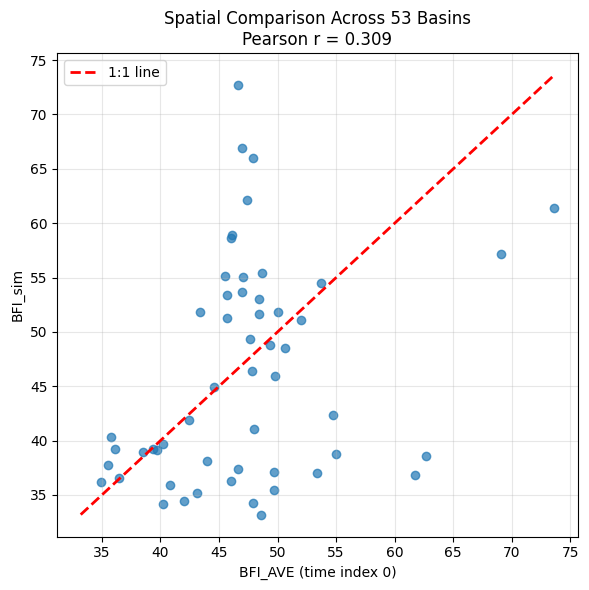

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# Load data
bfia = np.load("/home/s0shar47/scratch/salil/DPL/Outputs/PUB/1/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy")
bfis = np.load("/home/s0shar47/scratch/salil/DPL/Outputs/PUB/1/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy")

# Use the first time step from bfia
x = bfia[0, :]      # shape (53,)
y = bfis            # shape (53,)

# Remove NaNs if present
mask = np.isfinite(x) & np.isfinite(y)
x = x[mask]
y = y[mask]

# Spatial correlation across basins
r, p = pearsonr(x, y)

print(f"Spatial Correlation (Pearson r): {r:.4f}")
print(f"P-value: {p:.4e}")

# Scatter plot
plt.figure(figsize=(6, 6))
plt.scatter(x, y, alpha=0.7)

# 1:1 line
min_val = min(x.min(), y.min())
max_val = max(x.max(), y.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='1:1 line')

plt.xlabel('BFI_AVE (time index 0)')
plt.ylabel('BFI_sim')
plt.title(f'Spatial Comparison Across 53 Basins\nPearson r = {r:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Combined Pearson r = 0.6580
P-value = 3.4688e-67
Number of points = 531


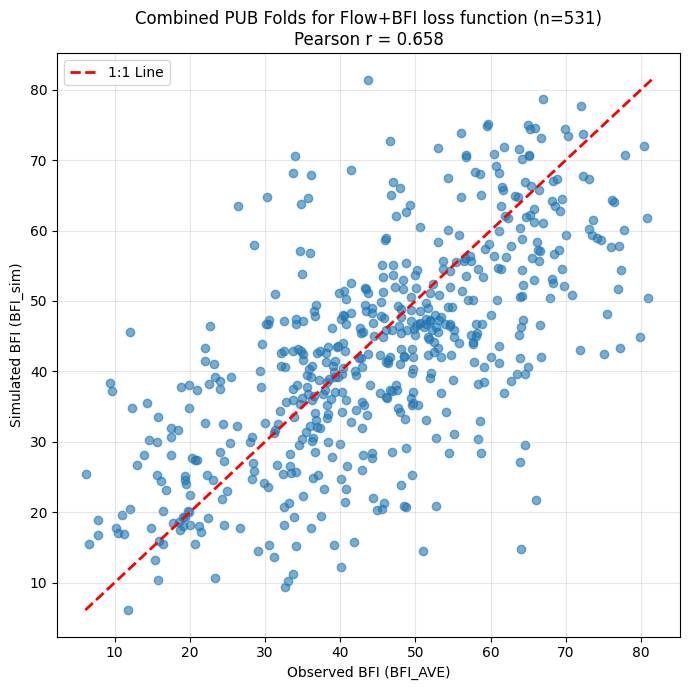

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

all_x = []
all_y = []

for i in range(1, 11):

    bfia = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy"
    )

    bfis = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy"
    )

    x = bfia[0, :]
    y = bfis

    mask = np.isfinite(x) & np.isfinite(y)

    all_x.extend(x[mask])
    all_y.extend(y[mask])

# Convert to arrays
all_x = np.array(all_x)
all_y = np.array(all_y)

# Overall spatial correlation across all folds
r, p = pearsonr(all_x, all_y)

print(f"Combined Pearson r = {r:.4f}")
print(f"P-value = {p:.4e}")
print(f"Number of points = {len(all_x)}")

# Plot
plt.figure(figsize=(7, 7))
plt.scatter(all_x, all_y, alpha=0.6)

# 1:1 line
min_val = min(all_x.min(), all_y.min())
max_val = max(all_x.max(), all_y.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    lw=2,
    label='1:1 Line'
)

plt.xlabel('Observed BFI (BFI_AVE)')
plt.ylabel('Simulated BFI (BFI_sim)')
plt.title(f'Combined PUB Folds for Flow+BFI loss function (n={len(all_x)})\nPearson r = {r:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Combined Pearson r = 0.5167
P-value = 1.4036e-37
Number of points = 531


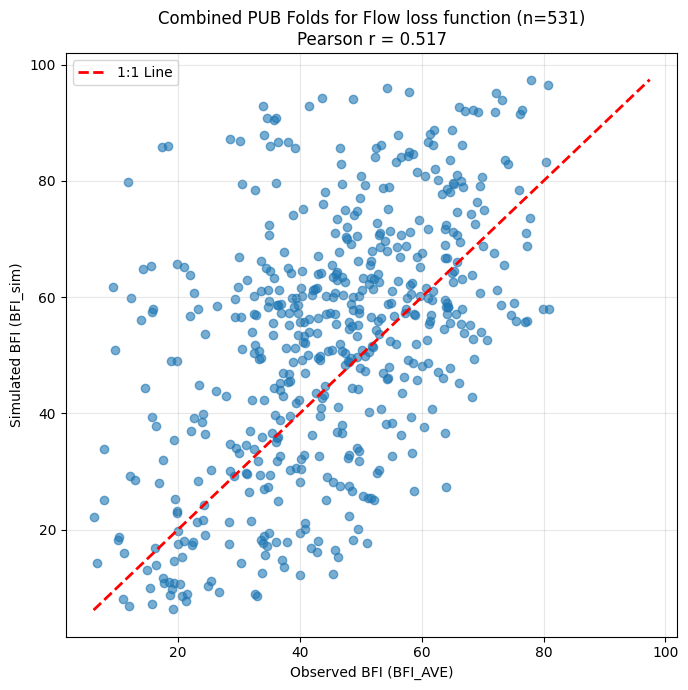

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

all_x = []
all_y = []

for i in range(1, 11):

    bfia = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy"
    )

    bfis = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB_flow/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy"
    )

    x = bfia[0, :]
    y = bfis

    mask = np.isfinite(x) & np.isfinite(y)

    all_x.extend(x[mask])
    all_y.extend(y[mask])

# Convert to arrays
all_x = np.array(all_x)
all_y = np.array(all_y)

# Overall spatial correlation across all folds
r, p = pearsonr(all_x, all_y)

print(f"Combined Pearson r = {r:.4f}")
print(f"P-value = {p:.4e}")
print(f"Number of points = {len(all_x)}")

# Plot
plt.figure(figsize=(7, 7))
plt.scatter(all_x, all_y, alpha=0.6)

# 1:1 line
min_val = min(all_x.min(), all_y.min())
max_val = max(all_x.max(), all_y.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    lw=2,
    label='1:1 Line'
)

plt.xlabel('Observed BFI (BFI_AVE)')
plt.ylabel('Simulated BFI (BFI_sim)')
plt.title(f'Combined PUB Folds for Flow loss function (n={len(all_x)})\nPearson r = {r:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [1]:
import numpy as np
np.load("/home/s0shar47/scratch/salil/CAMELS_531/BFI/f_obs_531_with_BFI.npy").shape

(531, 12418, 5)

In [2]:
folds = [[14185900, 12025000, 11162500, 2027000, 10396000, 
          3049000, 11528700, 7060710, 14216500, 4040500, 14141500, 
          2053800, 2481510, 5593900, 3463300, 7376000, 6878000, 8109700, 
          10336645, 10258000, 2014000, 7340300, 5399500, 5062500, 6784000, 
          14308990, 8165300, 3144000, 6440200, 12073500, 7148400, 3165000, 
          5503800, 2363000, 2481000, 5487980, 1137500, 10348850, 6876700, 
          6452000, 8082700, 14020000, 13331500, 13235000, 11475560, 1350000, 
          2065500, 5508805, 1414500, 4122200, 1532000, 1439500, 12388400, 
          1451800, 1516500, 6814000, 6352000, 2108000, 3164000, 14182500, 
          11383500, 1181000, 8178880, 9512280, 11274500, 2038850, 14362250], 
          [6291500, 7071500, 1557500, 7149000, 2296500, 8066200, 13310700, 
           11237500, 7301410, 1666500, 5057000, 5123400, 10336660, 1144000, 
           1544500, 1596500, 14139800, 6408700, 1586610, 2112360, 5595730, 11098000, 
           1605500, 1415000, 11143000, 1195100, 5414000, 11124500, 13340600, 11481200, 
           5556500, 3384450, 5592575, 7315200, 1545600, 4015330, 2350900, 8380500, 6353000, 
           3473000, 12092000, 6224000, 3504000, 7167500, 1350140, 1543000, 6409000, 2298608, 
           8195000, 5454000, 9065500, 1486000, 1170100, 7299670, 6311000, 14158500, 12411000, 
           1073000, 2472500, 2140991, 5466500, 1423000, 1121000, 2096846, 1440400, 12377150, 1613050], 
           [6622700, 2059500, 14166500, 6921070, 2051500, 3011800, 5129115, 1013500, 9430500, 6879650, 
            5087500, 2246000, 11522500, 7263295, 9378170, 3281500, 2102908, 9306242, 12375900, 
            12143600, 1550000, 2177000, 3021350, 8013000, 2149000, 1639500, 7373000, 3076600, 
            2196000, 10259200, 14306500, 6885500, 14138900, 11480390, 11176400, 7292500, 
            4256000, 7362587, 5585000, 2310947, 3237500, 6464500, 3592718, 4122500, 11478500, 
            9480000, 11476600, 1333000, 1644000, 12144000, 2051000, 8175000, 6614800, 5393500, 
            11451100, 4057510, 6339500, 9047700, 2479560, 5495000, 3604000, 4043050, 1567500, 
            6037500, 9223000, 7295000, 3340800], 
            [2028500, 5120500, 5525500, 12141300, 4115265, 
            3498500, 4063700, 8190500, 12167000, 6354000, 3069500, 9430600, 6917000, 5514500, 
            6447000, 10316500, 6280300, 12178100, 2152100, 6332515, 11284400, 6191500, 6479215, 
            9035800, 5489000, 1658500, 9210500, 1669000, 2015700, 2231000, 6889500, 1583500, 
            13011500, 11224500, 5412500, 2128000, 6221400, 8150800, 12056500, 6154410, 5501000, 
            5057200, 14185000, 5444000, 4105700, 4197170, 14309500, 1187300, 6289000, 2427250, 
            6360500, 4124000, 12095000, 3300400, 4127997, 10263500, 12115000, 3140000, 8164600, 
            3471500, 2053200, 1552500, 3357350, 3280700, 1667500, 2384540, 1543500], 
            [1594950, 8070200, 2430085, 8176900, 1413500, 7066000, 6903400, 6746095, 1606500, 
             2137727, 6468170, 2216180, 12186000, 14301000, 2395120, 6919500, 3460000, 14092750, 
             11468500, 6406000, 2235200, 2245500, 12025700, 2046000, 2415000, 8086290, 2464146, 
             2064000, 1134500, 12390700, 2178400, 3187500, 10329500, 12048000, 1365000, 6632400, 
             9497980, 3574500, 1638480, 2011400, 2111500, 6934000, 6450500, 3182500, 11180500, 
             8158700, 3213700, 3070500, 5584500, 5413500, 1485500, 7362100, 3186500, 1669520, 
             3026500, 2016000, 8377900, 12117000, 8023080, 4196800, 2027500, 7208500, 2111180, 
             10336740, 8200000, 3450000, 2143000], 
             [6441500, 2312200, 7184000, 4074950, 7195800, 3241500, 4224775, 1411300, 3170000,
              3479000, 5592050, 2202600, 2464360, 12020000, 11141280, 13083000, 1022500, 1568000, 
              6911900, 7226500, 13338500, 10173450, 2374500, 2314500, 2408540, 8029500, 8155200, 
              6477500, 3159540, 1632000, 8158810, 2465493, 13023000, 1620500, 11482500, 9513780, 
              12054000, 8378500, 7067000, 1057000, 2143040, 12082500, 1047000, 2193340, 4213075, 
              10205030, 2327100, 11180960, 2017500, 9510200, 10172700, 2450250, 7068000, 11230500, 
              1123000, 6188000, 1350080, 2371500, 12451000, 14306340, 6350000, 9378630, 8164300, 
              2215100, 4197100, 2055100, 1634500], 
              [11151300, 8196000, 7359610, 2092500, 5488200, 8014500, 2422500, 4127918, 
               6623800, 8086212, 14154500, 9107000, 3456500, 2315500, 3368000, 11264500, 
               7057500, 13340000, 2324400, 5408000, 14187000, 10023000, 4233000, 14325000, 
               5362000, 5458000, 8189500, 12114500, 6453600, 11274630, 10234500, 3439000, 
               11253310, 3488000, 2125000, 3238500, 2082950, 11532500, 1484100, 2221525, 
               14138800, 1591400, 3078000, 9492400, 3173000, 8070000, 3455500, 6278300, 6853800, 
               11299600, 8050800, 2381600, 1552000, 7335700, 2077200, 12115500, 2342933, 1434025, 
               12145500, 3500240, 11148900, 6431500, 6906800, 2070000, 9505200, 8267500, 8194200], 
               [11523200, 4027000, 2297310, 12013500, 1142500, 9066000, 1548500, 14222500, 9447800, 
                8269000, 4059500, 12381400, 9484000, 11266500, 3366500, 1580000, 8104900, 13313000, 
                12414500, 7180500, 1030500, 4045500, 6910800, 3285000, 6921200, 2018000, 12041200, 
                12358500, 1078000, 3346000, 4024430, 12043000, 12488500, 12035000, 5593575, 7197000, 
                9312600, 7290650, 7151500, 2112120, 2212600, 1435000, 1542810, 8103900, 1052500, 
                8066300, 1031500, 12147600, 14138870, 3066000, 14316700, 9034900, 2013000, 8190000, 
                1139800, 1440000, 3237280, 5591550, 8101000, 6479438, 1539000, 2469800, 3500000, 
                10244950, 7291000, 10249300, 1549500], [5507600, 13240000, 6803530, 10258500, 9066200, 
            4161580, 14400000, 6468250, 2479155, 12010000, 8025500, 6892000, 7346045, 5291000, 3028000, 14096850, 10166430, 5056000, 9497800, 2472000, 11473900, 2231342, 2118500, 8202700, 6447500, 2479300, 1632900, 7375000, 
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          1162500, 2369800, 13161500, 8324000, 12374250, 1547700, 14158790, 11381500, 9066300, 4185000, 4057800, 9505800, 6847900, 3015500, 5131500, 9505350, 3049800, 9386900, 2298123, 5495500, 2069700, 6803510, 2056900, 8198500, 7014500, 2198100, 2464000, 1491000, 7142300, 2011460, 6404000, 3010655, 2361000, 7083000, 10310500, 1055000, 9352900, 4221000, 1118300], [1054200, 14137000, 1139000, 14236200, 1169000, 1466500, 1487000, 14303200, 1510000, 1518862, 14305500, 1664000, 2074500, 2081500, 2297155, 2299950, 2300700, 2349900, 2372250, 2430615, 3050000, 3161000, 3180500, 3281100, 3291780, 3338780, 3364500, 4056500, 4213000, 4216418, 4296000, 6043500, 6339100, 6344600, 6470800, 6601000, 6888500, 6889200, 6918460, 7056000, 7145700, 7196900, 7261000, 7301500, 7315700, 8079600, 8164000, 8171300, 8271000, 9035900, 9081600, 9404450, 9484600, 9494000, 9508300, 10172800, 10242000, 10259000, 10343500, 12040500, 12147500, 12175500, 12189500, 12383500, 12447390, 13011900, 13018300, 13337000]]

for i, fold in enumerate(folds):
    print(f"Fold {i+1}: {len(fold)} basins")

print("Total basins:", sum(len(fold) for fold in folds))

Fold 1: 67 basins
Fold 2: 67 basins
Fold 3: 67 basins
Fold 4: 67 basins
Fold 5: 67 basins
Fold 6: 67 basins
Fold 7: 67 basins
Fold 8: 67 basins
Fold 9: 67 basins
Fold 10: 68 basins
Total basins: 671


In [3]:
np.array(folds, dtype=object)[0]

[14185900,
 12025000,
 11162500,
 2027000,
 10396000,
 3049000,
 11528700,
 7060710,
 14216500,
 4040500,
 14141500,
 2053800,
 2481510,
 5593900,
 3463300,
 7376000,
 6878000,
 8109700,
 10336645,
 10258000,
 2014000,
 7340300,
 5399500,
 5062500,
 6784000,
 14308990,
 8165300,
 3144000,
 6440200,
 12073500,
 7148400,
 3165000,
 5503800,
 2363000,
 2481000,
 5487980,
 1137500,
 10348850,
 6876700,
 6452000,
 8082700,
 14020000,
 13331500,
 13235000,
 11475560,
 1350000,
 2065500,
 5508805,
 1414500,
 4122200,
 1532000,
 1439500,
 12388400,
 1451800,
 1516500,
 6814000,
 6352000,
 2108000,
 3164000,
 14182500,
 11383500,
 1181000,
 8178880,
 9512280,
 11274500,
 2038850,
 14362250]

In [ ]:
np.load("/scratch/data/Camels_dataset_npy/f_obs_19801001_20141001.npy").shape
np.load("/scratch/data/Camels_dataset_npy/gageid.npy")

(671, 12418, 4)

In [15]:
np.load("/scratch/data/Camels_dataset_npy/gageid.npy")

array([ 1013500,  1022500,  1030500,  1031500,  1047000,  1052500,
        1054200,  1055000,  1057000,  1073000,  1078000,  1118300,
        1121000,  1123000,  1134500,  1137500,  1139000,  1139800,
        1142500,  1144000,  1162500,  1169000,  1170100,  1181000,
        1187300,  1195100,  1333000,  1350000,  1350080,  1350140,
        1365000,  1411300,  1413500,  1414500,  1415000,  1423000,
        1434025,  1435000,  1439500,  1440000,  1440400,  1451800,
        1466500,  1484100,  1485500,  1486000,  1487000,  1491000,
        1510000,  1516500,  1518862,  1532000,  1539000,  1542810,
        1543000,  1543500,  1544500,  1545600,  1547700,  1548500,
        1549500,  1550000,  1552000,  1552500,  1557500,  1567500,
        1568000,  1580000,  1583500,  1586610,  1591400,  1594950,
        1596500,  1605500,  1606500,  1613050,  1620500,  1632000,
        1632900,  1634500,  1638480,  1639500,  1644000,  1658500,
        1664000,  1666500,  1667500,  1669000,  1669520,  2011

In [9]:

import json   # load the subset ID
    # splitPath saves the basin ID of random groups
splitPath = '/home/s0shar47/scratch/dPLHBV_PUB_Feng/PUBsplitLst.txt'
with open(splitPath, 'r') as fp:
        testIDLst=json.load(fp)
len(testIDLst[0])
     

67

In [10]:
import baseflow
import pandas as pd

df = pd.read_csv(baseflow.example, index_col=0)
df_sta = pd.DataFrame(data=[[30, -28.4, 659], [-109.4, 33, 1611]],
                      index=df.columns, columns=['lon', 'lat', 'area'])
dfs, df_kge = baseflow.separation(df, df_sta, return_kge=True)
print(f'Best Method:\n{df_kge.idxmax(axis=1)}')

100%|██████████| 2/2 [00:11<00:00,  5.53s/it]

Best Method:
GRDC_1160815        EWMA
US_09447000     Eckhardt
dtype: object


Combined Pearson r = 0.2541
P-value = 6.6302e-02
Number of points = 53
RMSE: 14.820291519165039


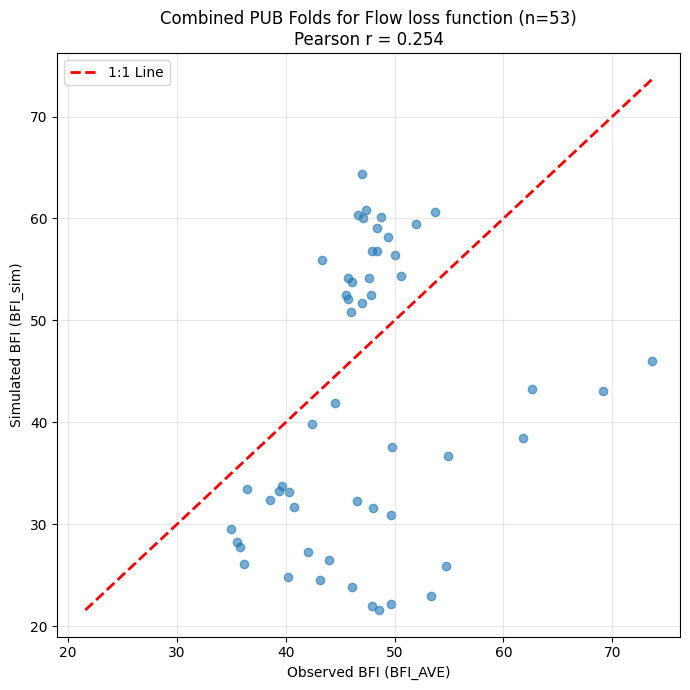

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

all_x = []
all_y = []

for i in range(1, 2):

    bfia = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy"
    )

    bfis = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy"
    )

    x = bfia[0, :]
    y = bfis

    mask = np.isfinite(x) & np.isfinite(y)

    all_x.extend(x[mask])
    all_y.extend(y[mask])

# Convert to arrays
all_x = np.array(all_x)
all_y = np.array(all_y)

# Overall spatial correlation across all folds
r, p = pearsonr(all_x, all_y)

print(f"Combined Pearson r = {r:.4f}")
print(f"P-value = {p:.4e}")
print(f"Number of points = {len(all_x)}")
rmse = np.sqrt(np.mean((all_x - all_y)**2))
print(f"RMSE: {rmse}")

# Plot
plt.figure(figsize=(7, 7))
plt.scatter(all_x, all_y, alpha=0.6)

# 1:1 line
min_val = min(all_x.min(), all_y.min())
max_val = max(all_x.max(), all_y.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    lw=2,
    label='1:1 Line'
)

plt.xlabel('Observed BFI (BFI_AVE)')
plt.ylabel('Simulated BFI (BFI_sim)')
plt.title(f'Combined PUB Folds for Flow loss function (n={len(all_x)})\nPearson r = {r:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Combined Pearson r = 0.2401
P-value = 8.3344e-02
Number of points = 53
RMSE: 13.896923065185547


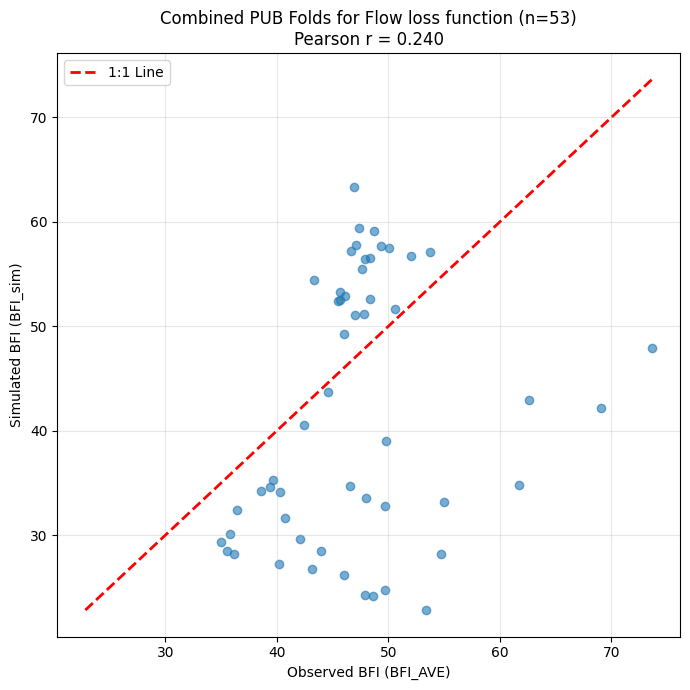

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

all_x = []
all_y = []

for i in range(1, 2):

    bfia = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy"
    )

    bfis = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try1/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy"
    )

    x = bfia[0, :]
    y = bfis

    mask = np.isfinite(x) & np.isfinite(y)

    all_x.extend(x[mask])
    all_y.extend(y[mask])

# Convert to arrays
all_x = np.array(all_x)
all_y = np.array(all_y)

# Overall spatial correlation across all folds
r, p = pearsonr(all_x, all_y)




print(f"Combined Pearson r = {r:.4f}")
print(f"P-value = {p:.4e}")
print(f"Number of points = {len(all_x)}")
rmse = np.sqrt(np.mean((all_x - all_y)**2))
print(f"RMSE: {rmse}")

# Plot
plt.figure(figsize=(7, 7))
plt.scatter(all_x, all_y, alpha=0.6)

# 1:1 line
min_val = min(all_x.min(), all_y.min())
max_val = max(all_x.max(), all_y.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    lw=2,
    label='1:1 Line'
)

plt.xlabel('Observed BFI (BFI_AVE)')
plt.ylabel('Simulated BFI (BFI_sim)')
plt.title(f'Combined PUB Folds for Flow loss function (n={len(all_x)})\nPearson r = {r:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Combined Pearson r = 0.2856
P-value = 3.8154e-02
Number of points = 53
RMSE: 15.035454750061035


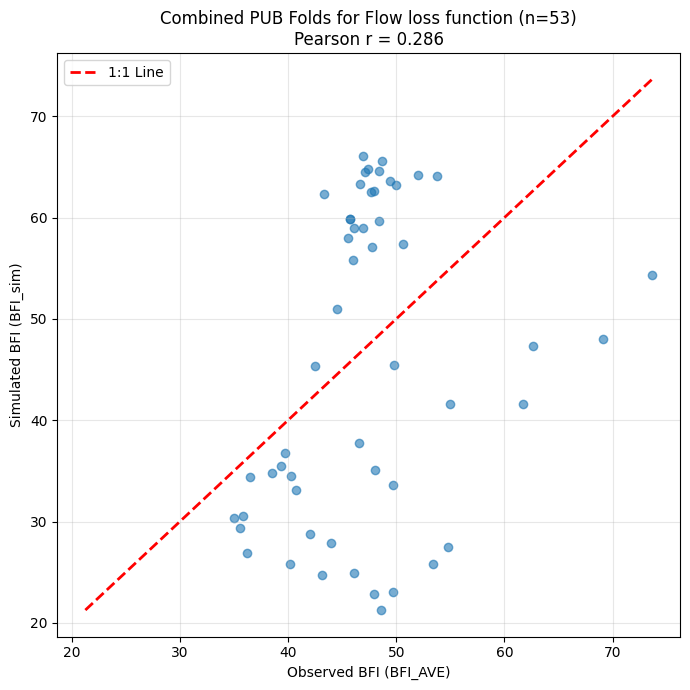

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

all_x = []
all_y = []

for i in range(1, 2):

    bfia = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy"
    )

    bfis = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try2/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy"
    )

    x = bfia[0, :]
    y = bfis

    mask = np.isfinite(x) & np.isfinite(y)

    all_x.extend(x[mask])
    all_y.extend(y[mask])

# Convert to arrays
all_x = np.array(all_x)
all_y = np.array(all_y)

# Overall spatial correlation across all folds
r, p = pearsonr(all_x, all_y)




print(f"Combined Pearson r = {r:.4f}")
print(f"P-value = {p:.4e}")
print(f"Number of points = {len(all_x)}")
rmse = np.sqrt(np.mean((all_x - all_y)**2))
print(f"RMSE: {rmse}")

# Plot
plt.figure(figsize=(7, 7))
plt.scatter(all_x, all_y, alpha=0.6)

# 1:1 line
min_val = min(all_x.min(), all_y.min())
max_val = max(all_x.max(), all_y.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    lw=2,
    label='1:1 Line'
)

plt.xlabel('Observed BFI (BFI_AVE)')
plt.ylabel('Simulated BFI (BFI_sim)')
plt.title(f'Combined PUB Folds for Flow loss function (n={len(all_x)})\nPearson r = {r:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Combined Pearson r = 0.2421
P-value = 8.0719e-02
Number of points = 53
RMSE: 14.41356372833252


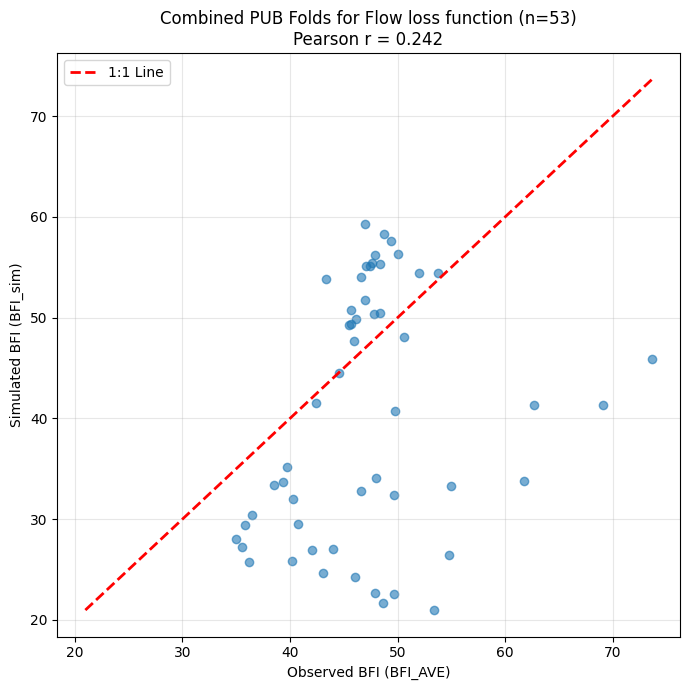

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

all_x = []
all_y = []

for i in range(1, 2):

    bfia = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Outputs/PUB/{i}/LSTM_HBV_capillary_E100_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy"
    )

    bfis = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try3/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy"
    )

    x = bfia[0, :]
    y = bfis

    mask = np.isfinite(x) & np.isfinite(y)

    all_x.extend(x[mask])
    all_y.extend(y[mask])

# Convert to arrays
all_x = np.array(all_x)
all_y = np.array(all_y)

# Overall spatial correlation across all folds
r, p = pearsonr(all_x, all_y)




print(f"Combined Pearson r = {r:.4f}")
print(f"P-value = {p:.4e}")
print(f"Number of points = {len(all_x)}")
rmse = np.sqrt(np.mean((all_x - all_y)**2))
print(f"RMSE: {rmse}")

# Plot
plt.figure(figsize=(7, 7))
plt.scatter(all_x, all_y, alpha=0.6)

# 1:1 line
min_val = min(all_x.min(), all_y.min())
max_val = max(all_x.max(), all_y.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    lw=2,
    label='1:1 Line'
)

plt.xlabel('Observed BFI (BFI_AVE)')
plt.ylabel('Simulated BFI (BFI_sim)')
plt.title(f'Combined PUB Folds for Flow loss function (n={len(all_x)})\nPearson r = {r:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Combined Pearson r = 0.2421
P-value = 8.0719e-02
Number of points = 53
RMSE: 14.41356372833252


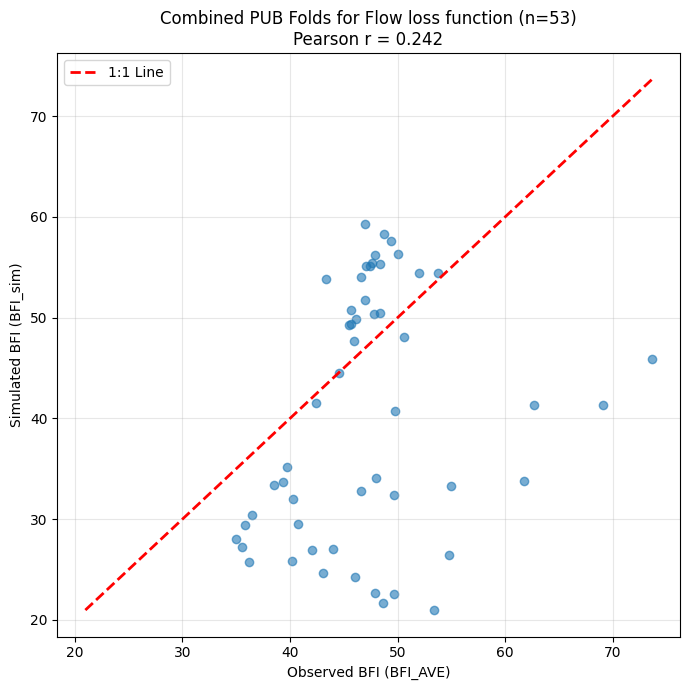

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

all_x = []
all_y = []

for i in range(1, 2):

    bfia = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try3/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy"
    )

    bfis = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try3/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy"
    )

    x = bfia[0, :]
    y = bfis

    mask = np.isfinite(x) & np.isfinite(y)

    all_x.extend(x[mask])
    all_y.extend(y[mask])

# Convert to arrays
all_x = np.array(all_x)
all_y = np.array(all_y)

# Overall spatial correlation across all folds
r, p = pearsonr(all_x, all_y)




print(f"Combined Pearson r = {r:.4f}")
print(f"P-value = {p:.4e}")
print(f"Number of points = {len(all_x)}")
rmse = np.sqrt(np.mean((all_x - all_y)**2))
print(f"RMSE: {rmse}")

# Plot
plt.figure(figsize=(7, 7))
plt.scatter(all_x, all_y, alpha=0.6)

# 1:1 line
min_val = min(all_x.min(), all_y.min())
max_val = max(all_x.max(), all_y.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    lw=2,
    label='1:1 Line'
)

plt.xlabel('Observed BFI (BFI_AVE)')
plt.ylabel('Simulated BFI (BFI_sim)')
plt.title(f'Combined PUB Folds for Flow loss function (n={len(all_x)})\nPearson r = {r:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Combined Pearson r = 0.8571
P-value = 2.6190e-16
Number of points = 53
RMSE: 4.5863471031188965


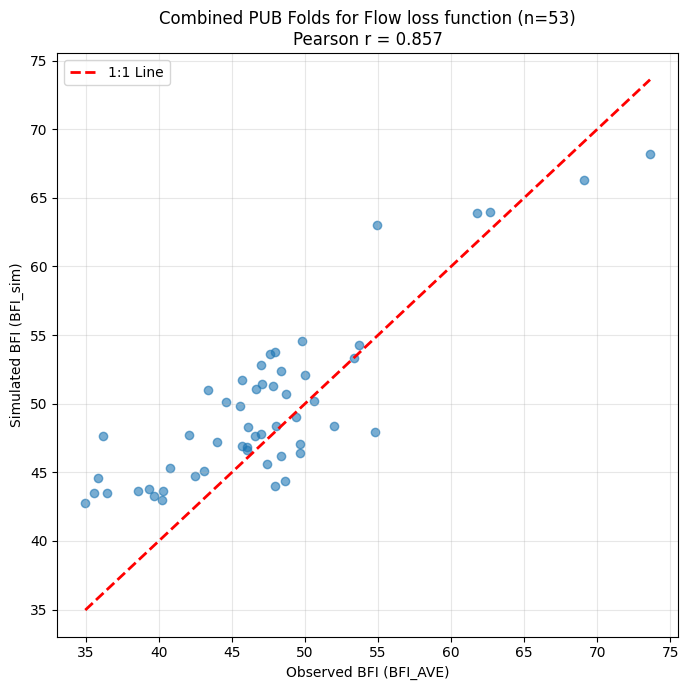

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

all_x = []
all_y = []

for i in range(1, 2):

    bfia = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try4/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy"
    )

    bfis = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try4/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy"
    )

    x = bfia[0, :]
    y = bfis

    mask = np.isfinite(x) & np.isfinite(y)

    all_x.extend(x[mask])
    all_y.extend(y[mask])

# Convert to arrays
all_x = np.array(all_x)
all_y = np.array(all_y)

# Overall spatial correlation across all folds
r, p = pearsonr(all_x, all_y)




print(f"Combined Pearson r = {r:.4f}")
print(f"P-value = {p:.4e}")
print(f"Number of points = {len(all_x)}")
rmse = np.sqrt(np.mean((all_x - all_y)**2))
print(f"RMSE: {rmse}")

# Plot
plt.figure(figsize=(7, 7))
plt.scatter(all_x, all_y, alpha=0.6)

# 1:1 line
min_val = min(all_x.min(), all_y.min())
max_val = max(all_x.max(), all_y.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    lw=2,
    label='1:1 Line'
)

plt.xlabel('Observed BFI (BFI_AVE)')
plt.ylabel('Simulated BFI (BFI_sim)')
plt.title(f'Combined PUB Folds for Flow loss function (n={len(all_x)})\nPearson r = {r:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Combined Pearson r = 0.8704
P-value = 2.5607e-17
Number of points = 53
RMSE: 4.237891674041748


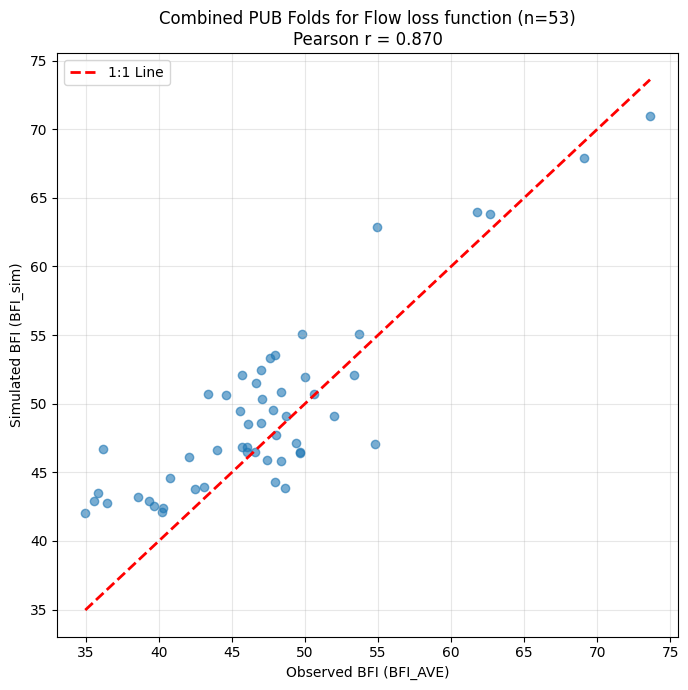

In [ ]:
import numpy as np  ##0.5, 0.5
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

all_x = []
all_y = []

for i in range(1, 2):

    bfia = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try5/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy"
    )

    bfis = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try5/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy"
    )

    x = bfia[0, :]
    y = bfis

    mask = np.isfinite(x) & np.isfinite(y)

    all_x.extend(x[mask])
    all_y.extend(y[mask])

# Convert to arrays
all_x = np.array(all_x)
all_y = np.array(all_y)

# Overall spatial correlation across all folds
r, p = pearsonr(all_x, all_y)




print(f"Combined Pearson r = {r:.4f}")
print(f"P-value = {p:.4e}")
print(f"Number of points = {len(all_x)}")
rmse = np.sqrt(np.mean((all_x - all_y)**2))
print(f"RMSE: {rmse}")

# Plot
plt.figure(figsize=(7, 7))
plt.scatter(all_x, all_y, alpha=0.6)

# 1:1 line
min_val = min(all_x.min(), all_y.min())
max_val = max(all_x.max(), all_y.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    lw=2,
    label='1:1 Line'
)

plt.xlabel('Observed BFI (BFI_AVE)')
plt.ylabel('Simulated BFI (BFI_sim)')
plt.title(f'Combined PUB Folds for Flow loss function (n={len(all_x)})\nPearson r = {r:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Combined Pearson r = 0.8469
P-value = 1.3365e-15
Number of points = 53
RMSE: 4.366572380065918


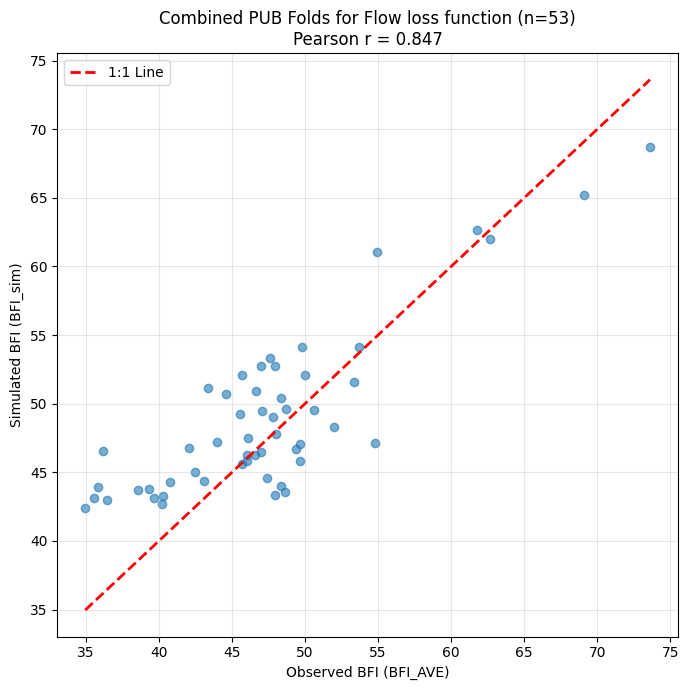

In [ ]:
import numpy as np    ##0.25, 0.25
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

all_x = []
all_y = []

for i in range(1, 2):

    bfia = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try6/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy"
    )

    bfis = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try6/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy"
    )

    x = bfia[0, :]
    y = bfis

    mask = np.isfinite(x) & np.isfinite(y)

    all_x.extend(x[mask])
    all_y.extend(y[mask])

# Convert to arrays
all_x = np.array(all_x)
all_y = np.array(all_y)

# Overall spatial correlation across all folds
r, p = pearsonr(all_x, all_y)




print(f"Combined Pearson r = {r:.4f}")
print(f"P-value = {p:.4e}")
print(f"Number of points = {len(all_x)}")
rmse = np.sqrt(np.mean((all_x - all_y)**2))
print(f"RMSE: {rmse}")

# Plot
plt.figure(figsize=(7, 7))
plt.scatter(all_x, all_y, alpha=0.6)

# 1:1 line
min_val = min(all_x.min(), all_y.min())
max_val = max(all_x.max(), all_y.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    lw=2,
    label='1:1 Line'
)

plt.xlabel('Observed BFI (BFI_AVE)')
plt.ylabel('Simulated BFI (BFI_sim)')
plt.title(f'Combined PUB Folds for Flow loss function (n={len(all_x)})\nPearson r = {r:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Combined Pearson r = 0.8571
P-value = 2.6190e-16
Number of points = 53
RMSE: 4.5863471031188965


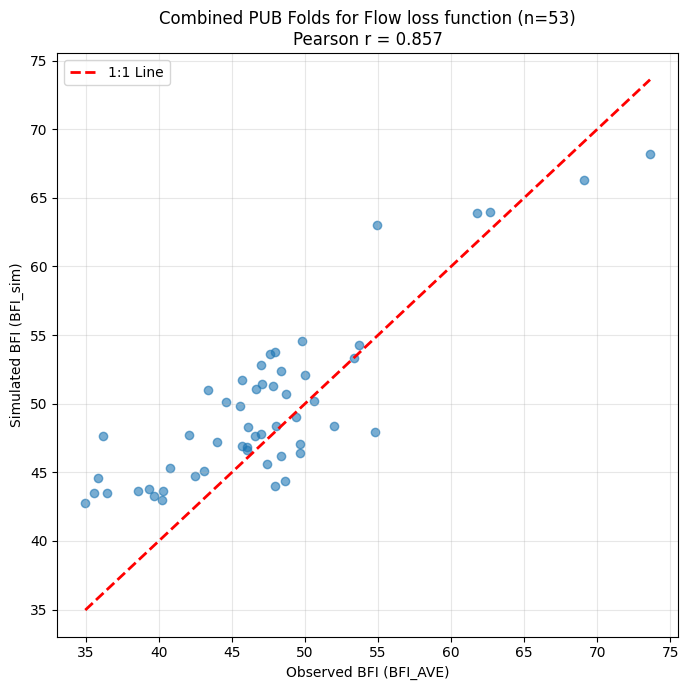

In [ ]:
import numpy as np   ###1,1
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

all_x = []
all_y = []

for i in range(1, 2):

    bfia = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try7/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy"
    )

    bfis = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try7/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy"
    )

    x = bfia[0, :]
    y = bfis

    mask = np.isfinite(x) & np.isfinite(y)

    all_x.extend(x[mask])
    all_y.extend(y[mask])

# Convert to arrays
all_x = np.array(all_x)
all_y = np.array(all_y)

# Overall spatial correlation across all folds
r, p = pearsonr(all_x, all_y)




print(f"Combined Pearson r = {r:.4f}")
print(f"P-value = {p:.4e}")
print(f"Number of points = {len(all_x)}")
rmse = np.sqrt(np.mean((all_x - all_y)**2))
print(f"RMSE: {rmse}")

# Plot
plt.figure(figsize=(7, 7))
plt.scatter(all_x, all_y, alpha=0.6)

# 1:1 line
min_val = min(all_x.min(), all_y.min())
max_val = max(all_x.max(), all_y.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    lw=2,
    label='1:1 Line'
)

plt.xlabel('Observed BFI (BFI_AVE)')
plt.ylabel('Simulated BFI (BFI_sim)')
plt.title(f'Combined PUB Folds for Flow loss function (n={len(all_x)})\nPearson r = {r:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Combined Pearson r = 0.8652
P-value = 6.6142e-17
Number of points = 53
RMSE: 4.071102142333984


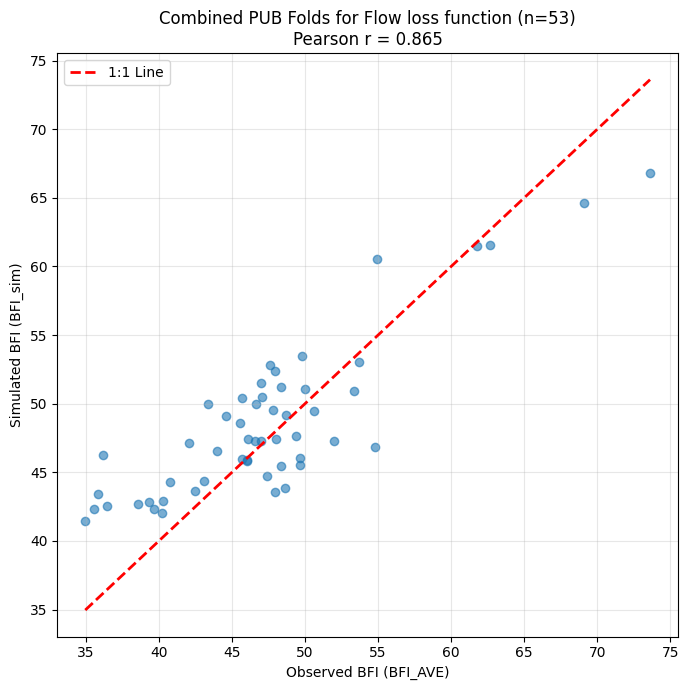

In [23]:
import numpy as np   ###2,2
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

all_x = []
all_y = []

for i in range(1, 2):

    bfia = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try8/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy"
    )

    bfis = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try8/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy"
    )

    x = bfia[0, :]
    y = bfis

    mask = np.isfinite(x) & np.isfinite(y)

    all_x.extend(x[mask])
    all_y.extend(y[mask])

# Convert to arrays
all_x = np.array(all_x)
all_y = np.array(all_y)

# Overall spatial correlation across all folds
r, p = pearsonr(all_x, all_y)




print(f"Combined Pearson r = {r:.4f}")
print(f"P-value = {p:.4e}")
print(f"Number of points = {len(all_x)}")
rmse = np.sqrt(np.mean((all_x - all_y)**2))
print(f"RMSE: {rmse}")

# Plot
plt.figure(figsize=(7, 7))
plt.scatter(all_x, all_y, alpha=0.6)

# 1:1 line
min_val = min(all_x.min(), all_y.min())
max_val = max(all_x.max(), all_y.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    lw=2,
    label='1:1 Line'
)

plt.xlabel('Observed BFI (BFI_AVE)')
plt.ylabel('Simulated BFI (BFI_sim)')
plt.title(f'Combined PUB Folds for Flow loss function (n={len(all_x)})\nPearson r = {r:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Combined Pearson r = 0.8573
P-value = 2.5266e-16
Number of points = 53
RMSE: 4.4165239334106445


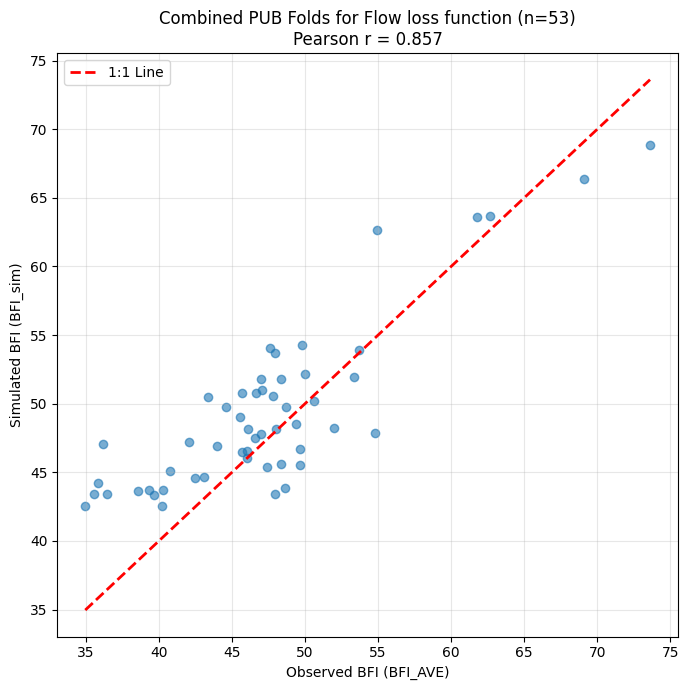

In [24]:
import numpy as np   ###3,3
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

all_x = []
all_y = []

for i in range(1, 2):

    bfia = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try9/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy"
    )

    bfis = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try9/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy"
    )

    x = bfia[0, :]
    y = bfis

    mask = np.isfinite(x) & np.isfinite(y)

    all_x.extend(x[mask])
    all_y.extend(y[mask])

# Convert to arrays
all_x = np.array(all_x)
all_y = np.array(all_y)

# Overall spatial correlation across all folds
r, p = pearsonr(all_x, all_y)




print(f"Combined Pearson r = {r:.4f}")
print(f"P-value = {p:.4e}")
print(f"Number of points = {len(all_x)}")
rmse = np.sqrt(np.mean((all_x - all_y)**2))
print(f"RMSE: {rmse}")

# Plot
plt.figure(figsize=(7, 7))
plt.scatter(all_x, all_y, alpha=0.6)

# 1:1 line
min_val = min(all_x.min(), all_y.min())
max_val = max(all_x.max(), all_y.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    lw=2,
    label='1:1 Line'
)

plt.xlabel('Observed BFI (BFI_AVE)')
plt.ylabel('Simulated BFI (BFI_sim)')
plt.title(f'Combined PUB Folds for Flow loss function (n={len(all_x)})\nPearson r = {r:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



Combined Pearson r = 0.2214
P-value = 1.1105e-01
Number of points = 53
RMSE: 14.238879203796387


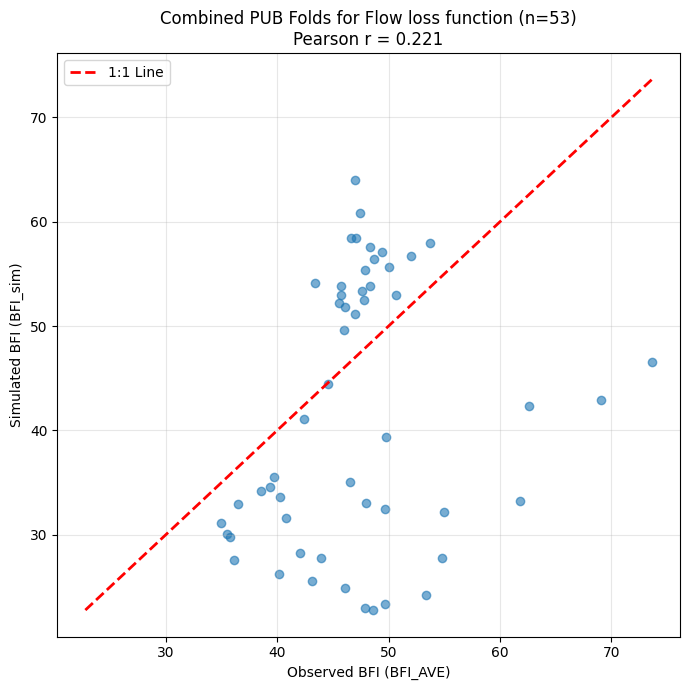

In [25]:
import numpy as np   ###3,3
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

all_x = []
all_y = []

for i in range(1, 2):

    bfia = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try10/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy"
    )

    bfis = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try10/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy"
    )

    x = bfia[0, :]
    y = bfis

    mask = np.isfinite(x) & np.isfinite(y)

    all_x.extend(x[mask])
    all_y.extend(y[mask])

# Convert to arrays
all_x = np.array(all_x)
all_y = np.array(all_y)

# Overall spatial correlation across all folds
r, p = pearsonr(all_x, all_y)




print(f"Combined Pearson r = {r:.4f}")
print(f"P-value = {p:.4e}")
print(f"Number of points = {len(all_x)}")
rmse = np.sqrt(np.mean((all_x - all_y)**2))
print(f"RMSE: {rmse}")

# Plot
plt.figure(figsize=(7, 7))
plt.scatter(all_x, all_y, alpha=0.6)

# 1:1 line
min_val = min(all_x.min(), all_y.min())
max_val = max(all_x.max(), all_y.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    lw=2,
    label='1:1 Line'
)

plt.xlabel('Observed BFI (BFI_AVE)')
plt.ylabel('Simulated BFI (BFI_sim)')
plt.title(f'Combined PUB Folds for Flow loss function (n={len(all_x)})\nPearson r = {r:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



Combined Pearson r = 0.8535
P-value = 4.6989e-16
Number of points = 53
RMSE: 4.4801154136657715


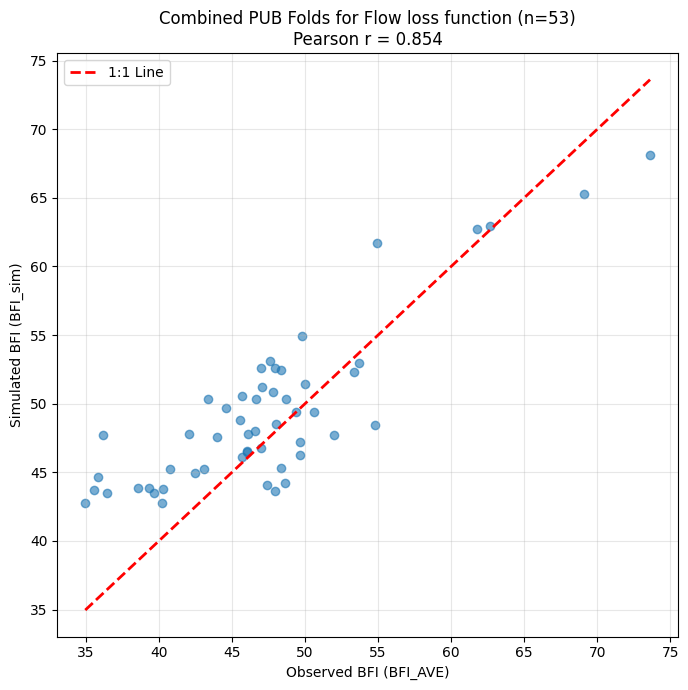

In [ ]:
import numpy as np   ###3,1
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

all_x = []
all_y = []

for i in range(1, 2):

    bfia = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try12/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_AVE.npy"
    )

    bfis = np.load(
        f"/home/s0shar47/scratch/salil/DPL/Tuning/Try12/LSTM_HBV_capillary_E1_R365_B100_H256_tr1989_1999_n16_0/hydro_stat_/ts1989_1999/BFI_sim.npy"
    )

    x = bfia[0, :]
    y = bfis

    mask = np.isfinite(x) & np.isfinite(y)

    all_x.extend(x[mask])
    all_y.extend(y[mask])

# Convert to arrays
all_x = np.array(all_x)
all_y = np.array(all_y)

# Overall spatial correlation across all folds
r, p = pearsonr(all_x, all_y)




print(f"Combined Pearson r = {r:.4f}")
print(f"P-value = {p:.4e}")
print(f"Number of points = {len(all_x)}")
rmse = np.sqrt(np.mean((all_x - all_y)**2))
print(f"RMSE: {rmse}")

# Plot
plt.figure(figsize=(7, 7))
plt.scatter(all_x, all_y, alpha=0.6)

# 1:1 line
min_val = min(all_x.min(), all_y.min())
max_val = max(all_x.max(), all_y.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--',
    lw=2,
    label='1:1 Line'
)

plt.xlabel('Observed BFI (BFI_AVE)')
plt.ylabel('Simulated BFI (BFI_sim)')
plt.title(f'Combined PUB Folds for Flow loss function (n={len(all_x)})\nPearson r = {r:.3f}')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



In [54]:
import numpy as np

# This list will hold the individual NSE scores for all 531 basins
all_nse_scores = []

for i in range(1, 11):
    # 1. Load data for the current fold
    sim= np.load(f"/home/s0shar47/scratch/PUB_Output_DAYMET/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy")
    ob= np.load(f"/home/s0shar47/scratch/PUB_Output_DAYMET/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/00060_Mean.npy")
    # sim = np.load(f"/home/s0shar47/scratch/Output_Feng2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/hydro_stat_/ts1989_1999/flow_sim.npy")
    # ob = np.load(f"/home/s0shar47/scratch/Output_Feng2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/hydro_stat_/ts1989_1999/00060_Mean.npy")
    
    # 2. Squeeze the last dimension of sim -> shape becomes (3286, num_basins)
    sim_squeezed = np.squeeze(sim, axis=-1)
    
    # 3. Calculate NSE components for the basins in THIS specific fold
    numerator = np.sum((ob - sim_squeezed) ** 2, axis=0)
    ob_mean = np.mean(ob, axis=0)
    denominator = np.sum((ob - ob_mean) ** 2, axis=0)
    
    # nse_per_basin will have a shape of (53,) for nine folds, and (54,) for one fold
    nse_per_basin = 1 - (numerator / denominator)
    nse_per_basin = nse_per_basin[~np.isnan(nse_per_basin)]
    # 4. Save these scores to our master list
    all_nse_scores.append(nse_per_basin)

# 5. Safely concatenate the 1D score arrays into a single array of 531 elements
total_nse_pool = np.concatenate(all_nse_scores)

# 6. Calculate your overall cross-validation median NSE
overall_median_nse = np.median(total_nse_pool)

print(f"Successfully processed {len(all_nse_scores)} folds for PUB flow.")
print(f"Total number of basin NSE scores pooled: {total_nse_pool.shape[0]}") # Should equal 531
print(f"Overall Cross-Validation Median NSE: {overall_median_nse:.4f}")

Successfully processed 10 folds for PUB flow.
Total number of basin NSE scores pooled: 448
Overall Cross-Validation Median NSE: 0.7018


In [55]:
import numpy as np

# This list will hold the individual NSE scores for all 531 basins
all_nse_scores = []

for i in range(1, 11):
    # 1. Load data for the current fold
    sim = np.load(f"/home/s0shar47/scratch/PUB_Output_DAYMET/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy")
    ob = np.load(f"/home/s0shar47/scratch/PUB_Output_DAYMET/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/00060_Mean.npy")
    
    # 2. Squeeze the last dimension of sim -> shape becomes (3286, num_basins)
    sim_squeezed = np.squeeze(sim, axis=-1)
    
    # 3. Calculate NSE components for the basins in THIS specific fold
    numerator = np.sum((ob - sim_squeezed) ** 2, axis=0)
    ob_mean = np.mean(ob, axis=0)
    denominator = np.sum((ob - ob_mean) ** 2, axis=0)
    
    # ==========================================
    # DATA CHECK / DIAGNOSTIC BLOCK
    # ==========================================
    nan_in_ob = np.isnan(ob).sum()
    nan_in_sim = np.isnan(sim_squeezed).sum()
    zero_variance_basins = np.sum(denominator == 0)
    
    if nan_in_ob > 0 or nan_in_sim > 0 or zero_variance_basins > 0:
        print(f"--- [FOLD {i}] Data Issues Detected ---")
        if nan_in_ob > 0:
            print(f"  ⚠️ Found {nan_in_ob} total NaN values in 'ob' (observed data).")
        if nan_in_sim > 0:
            print(f"  ⚠️ Found {nan_in_sim} total NaN values in 'sim' (simulated data).")
        if zero_variance_basins > 0:
            print(f"  ⚠️ Found {zero_variance_basins} basin(s) where observed flow variance is 0 (denominator=0).")
            # Print the exact column index of the flatlining basin(s) in this fold
            print(f"     Problem basin indices in fold {i}: {np.where(denominator == 0)[0]}")
        print("-" * 40)
    # ==========================================
    
    # nse_per_basin will have a shape of (53,) for nine folds, and (54,) for one fold
    nse_per_basin = 1 - (numerator / denominator)
    
    # Check if NSE itself resulted in NaNs before we strip them out
    num_nse_nans = np.isnan(nse_per_basin).sum()
    if num_nse_nans > 0:
        print(f"[FOLD {i}] Stripping out {num_nse_nans} NaN value(s) from nse_per_basin.")

    nse_per_basin = nse_per_basin[~np.isnan(nse_per_basin)]
    
    # 4. Save these scores to our master list
    all_nse_scores.append(nse_per_basin)

# 5. Safely concatenate the 1D score arrays into a single array of 531 elements
total_nse_pool = np.concatenate(all_nse_scores)

# 6. Calculate your overall cross-validation median NSE
overall_median_nse = np.median(total_nse_pool)

print("\n=== FINAL RESULTS ===")
print(f"Successfully processed {len(all_nse_scores)} folds for PUB flow.")
print(f"Total number of basin NSE scores pooled: {total_nse_pool.shape[0]}") # Should equal 531
print(f"Overall Cross-Validation Median NSE: {overall_median_nse:.4f}")

--- [FOLD 1] Data Issues Detected ---
  ⚠️ Found 29574 total NaN values in 'ob' (observed data).
----------------------------------------
[FOLD 1] Stripping out 9 NaN value(s) from nse_per_basin.
--- [FOLD 2] Data Issues Detected ---
  ⚠️ Found 32860 total NaN values in 'ob' (observed data).
----------------------------------------
[FOLD 2] Stripping out 10 NaN value(s) from nse_per_basin.
--- [FOLD 3] Data Issues Detected ---
  ⚠️ Found 29574 total NaN values in 'ob' (observed data).
----------------------------------------
[FOLD 3] Stripping out 9 NaN value(s) from nse_per_basin.
--- [FOLD 4] Data Issues Detected ---
  ⚠️ Found 23002 total NaN values in 'ob' (observed data).
----------------------------------------
[FOLD 4] Stripping out 7 NaN value(s) from nse_per_basin.
--- [FOLD 5] Data Issues Detected ---
  ⚠️ Found 29574 total NaN values in 'ob' (observed data).
----------------------------------------
[FOLD 5] Stripping out 9 NaN value(s) from nse_per_basin.
--- [FOLD 6] Data I

In [3]:
import numpy as np

all_sim_values = []
all_ob_values = []

for i in range(1, 11):
    # 1. Load data
    sim = np.load(f"/home/s0shar47/scratch/Output_Feng2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/hydro_stat_/ts1989_1999/flow_sim.npy")
    ob = np.load(f"/home/s0shar47/scratch/Output_Feng2/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/hydro_stat_/ts1989_1999/00060_Mean.npy")
    
    # 2. Squeeze the simulated data to match observed shape
    sim_squeezed = np.squeeze(sim, axis=-1)
    
    # 3. Flatten both arrays to 1D vectors and append to our lists
    # This turns a (3286, 53) array into a flat vector of 174,158 values
    all_sim_values.append(sim_squeezed.flatten())
    all_ob_values.append(ob.flatten())

# 4. Concatenate all 10 flat vectors into one massive 1D array
flat_sim = np.concatenate(all_sim_values)
flat_ob = np.concatenate(all_ob_values)

# 5. Compute the global NSE across all 1,744,866 points combined
numerator = np.sum((flat_ob - flat_sim) ** 2)
global_ob_mean = np.mean(flat_ob)
denominator = np.sum((flat_ob - global_ob_mean) ** 2)

global_nse = 1 - (numerator / denominator)

print(f"Total simulated data points extracted: {flat_sim.shape[0]}")
print(f"Total observed data points extracted:  {flat_ob.shape[0]}")
print(f"Overall Global NSE for PUB flow: {global_nse:.4f}")

Total simulated data points extracted: 1744866
Total observed data points extracted:  1744866
Overall Global NSE for PUB flow: 0.7701


In [119]:
###Feng's Fold

import os
import json
import numpy as np
import pandas as pd

# --------------------------------------------------
# Paths
# --------------------------------------------------
gageid_file = "/scratch/data/Camels_dataset_npy/gageid.npy"
attr_file = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671.npy"
forcing_file = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy"

pubsplit_file = "/home/s0shar47/scratch/dPLHBV_PUB_Feng/PUBsplitLst.txt"
camels531_file = "/scratch/data/CAMELS_531.csv"

out_root = "/home/s0shar47/scratch/Daymet_Folds"

# --------------------------------------------------
# Load data
# --------------------------------------------------
gageids = np.load(gageid_file)
attrs = np.load(attr_file)
forcings = np.load(forcing_file)

print("gageids:", gageids.shape)
print("attrs:", attrs.shape)
print("forcings:", forcings.shape)

with open(pubsplit_file, "r") as f:
    folds = json.load(f)

print("Number of folds:", len(folds))

# --------------------------------------------------
# Load 531 basin IDs
# --------------------------------------------------
df531 = pd.read_csv(camels531_file)

# Use the first column if unsure
test531_ids = set(df531["Gauge ID"].astype(str))

print("531 basins:", len(test531_ids))

# --------------------------------------------------
# Convert gageids to strings for matching
# --------------------------------------------------
gageids_str = np.array([str(int(x)) if str(x).replace('.', '').isdigit()
                        else str(x) for x in gageids])

# --------------------------------------------------
# Create folds
# --------------------------------------------------
for fold_num in range(10):

    fold_dir = os.path.join(out_root, str(fold_num + 1))
    train_dir = os.path.join(fold_dir, "train")
    test_dir = os.path.join(fold_dir, "test")

    os.makedirs(train_dir, exist_ok=True)
    os.makedirs(test_dir, exist_ok=True)

    # ----------------------------------------------
    # Test basins = current fold ∩ CAMELS_531
    # ----------------------------------------------
    current_fold = set(map(str, folds[fold_num]))

    test_ids = current_fold.intersection(test531_ids)

    # ----------------------------------------------
    # Train basins = all other folds
    # ----------------------------------------------
    train_ids = set()

    for j in range(10):
        if j != fold_num:
            train_ids.update(map(str, folds[j]))

    # ----------------------------------------------
    # Find indices
    # ----------------------------------------------
    train_idx = np.where(np.isin(gageids_str, list(train_ids)))[0]
    test_idx = np.where(np.isin(gageids_str, list(test_ids)))[0]

    print(
        f"Fold {fold_num+1}: "
        f"train={len(train_idx)} basins, "
        f"test={len(test_idx)} basins"
    )

    # ----------------------------------------------
    # Save train
    # ----------------------------------------------
    np.save(
        os.path.join(train_dir, "gageid.npy"),
        gageids[train_idx]
    )

    np.save(
        os.path.join(train_dir, "daymet_19800101_20141231_attr_671.npy"),
        attrs[train_idx]
    )

    np.save(
        os.path.join(train_dir, "daymet_19800101_20141231_forcing_671.npy"),
        forcings[train_idx]
    )

    # ----------------------------------------------
    # Save test
    # ----------------------------------------------
    np.save(
        os.path.join(test_dir, "gageid.npy"),
        gageids[test_idx]
    )

    np.save(
        os.path.join(test_dir, "daymet_19800101_20141231_attr_671.npy"),
        attrs[test_idx]
    )

    np.save(
        os.path.join(test_dir, "daymet_19800101_20141231_forcing_671.npy"),
        forcings[test_idx]
    )

print("Done.")

gageids: (671,)
attrs: (671, 35)
forcings: (671, 12784, 15)
Number of folds: 10
531 basins: 531
Fold 1: train=604 basins, test=52 basins
Fold 2: train=604 basins, test=54 basins
Fold 3: train=604 basins, test=52 basins
Fold 4: train=604 basins, test=51 basins
Fold 5: train=604 basins, test=54 basins
Fold 6: train=604 basins, test=47 basins
Fold 7: train=604 basins, test=56 basins
Fold 8: train=604 basins, test=55 basins
Fold 9: train=604 basins, test=54 basins
Fold 10: train=603 basins, test=56 basins
Done.


In [45]:
import json

# Your 15 final forcing names
forcing_names = [ "prcp(mm/day)",  "PEVAP", "00060_Mean", "tmean(C)"]

# Your target Table A1 attribute names (or whichever subset your model uses)
attr_names = [
    'p_mean', 'pet_mean', 'p_seasonality', 'frac_snow', 'aridity',
 'high_prec_freq', 'high_prec_dur', 'low_prec_freq', 'low_prec_dur',
 'elev_mean', 'slope_mean', 'area_gages2', 'frac_forest', 'lai_max',
 'lai_diff', 'gvf_max', 'gvf_diff', 'dom_land_cover_frac',
 'dom_land_cover', 'root_depth_50', 'soil_depth_pelletier',
 'soil_depth_statsgo', 'soil_porosity', 'soil_conductivity',
 'max_water_content', 'sand_frac', 'silt_frac', 'clay_frac',
 'geol_1st_class', 'glim_1st_class_frac', 'geol_2nd_class',
 'glim_2nd_class_frac', 'carbonate_rocks_frac', 'geol_porostiy',
 'geol_permeability'
]

# File paths from your pipeline configuration
forcing_path = "/scratch/data/CAMELS_FORCING/slim_daymet_19800101_20141231_forcing_671_name.json"
attr_path = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671_name.json"

# Write the forcing names array
with open(forcing_path, 'w') as f:
    json.dump(forcing_names, f, indent=2)

# Write the attribute names array
with open(attr_path, 'w') as f:
    json.dump(attr_names, f, indent=2)

print("Both JSON files successfully repaired and formatted!")

Both JSON files successfully repaired and formatted!


In [46]:
import os
import shutil

root = "/home/s0shar47/scratch/Daymet_Folds"

attr_json = "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671_name.json"
forcing_json = "/scratch/data/CAMELS_FORCING/slim_daymet_19800101_20141231_forcing_671_name.json"

for fold in range(1, 11):
    for split in ["train", "test"]:

        folder = os.path.join(root, str(fold), split)

        shutil.copy(
            attr_json,
            os.path.join(folder, "daymet_19800101_20141231_attr_671_name.json")
        )

        shutil.copy(
            forcing_json,
            os.path.join(folder, "slim_daymet_19800101_20141231_forcing_671_name.json")
        )

print("JSON files copied to all train/test folders.")

JSON files copied to all train/test folders.


In [49]:
! pip install pyarrow

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.8/48.8 MB 50.8 MB/s eta 0:00:0000:0100:01


In [50]:
pd.read_feather(forcing_file)

ArrowKeyError: No type extension with name arrow.py_extension_type found

In [4]:
import numpy as np

attr= np.load("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_attr_671.npy")
attr.shape

(671, 35)

In [5]:
forcing= np.load("/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy")
forcing.shape

(671, 12784, 15)

In [ ]:
import numpy as np

# This list will hold the individual NSE scores for all 531 basins
all_nse_scores = []

for i in range(1, 2):
    # 1. Load data for the current fold
    sim= np.load(f"/home/s0shar47/scratch/PUB_Output_DAYMET/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy")
    ob= np.load(f"/home/s0shar47/scratch/PUB_Output_DAYMET/{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/00060_Mean.npy")


numpy.ndarray

In [67]:
# Assuming you want to run this check inside your fold loop where 'sim' and 'ob' are loaded:

# Loop through each basin in the current fold (e.g., up to 53 or 54 basins depending on the fold)
num_basins_in_fold = sim.shape[1] 

for i in range(num_basins_in_fold):
    # Count NaNs in simulated data for this basin
    # sim[:, i, :] has shape (3286, 1)
    nan_count_sim = np.isnan(sim[:, i, :]).sum()
    
    # Count NaNs in observed data for this basin
    # ob[:, i] has shape (3286,)
    nan_count_ob = np.isnan(ob[:, i]).sum()
    
    print(f"Basin Index: {i:<2} | NaNs in Sim: {nan_count_sim:<5} | NaNs in Ob: {nan_count_ob:<5}")

Basin Index: 0  | NaNs in Sim: 0     | NaNs in Ob: 0    
Basin Index: 1  | NaNs in Sim: 0     | NaNs in Ob: 0    
Basin Index: 2  | NaNs in Sim: 0     | NaNs in Ob: 0    
Basin Index: 3  | NaNs in Sim: 0     | NaNs in Ob: 0    
Basin Index: 4  | NaNs in Sim: 0     | NaNs in Ob: 0    
Basin Index: 5  | NaNs in Sim: 0     | NaNs in Ob: 0    
Basin Index: 6  | NaNs in Sim: 0     | NaNs in Ob: 0    
Basin Index: 7  | NaNs in Sim: 0     | NaNs in Ob: 0    
Basin Index: 8  | NaNs in Sim: 0     | NaNs in Ob: 0    
Basin Index: 9  | NaNs in Sim: 0     | NaNs in Ob: 0    
Basin Index: 10 | NaNs in Sim: 0     | NaNs in Ob: 0    
Basin Index: 11 | NaNs in Sim: 0     | NaNs in Ob: 0    
Basin Index: 12 | NaNs in Sim: 0     | NaNs in Ob: 0    
Basin Index: 13 | NaNs in Sim: 0     | NaNs in Ob: 0    
Basin Index: 14 | NaNs in Sim: 0     | NaNs in Ob: 3286 
Basin Index: 15 | NaNs in Sim: 0     | NaNs in Ob: 0    
Basin Index: 16 | NaNs in Sim: 0     | NaNs in Ob: 0    
Basin Index: 17 | NaNs in Sim: 

In [87]:
np.load("/home/s0shar47/scratch/Daymet_Folds/1/test/daymet_19800101_20141231_forcing_671.npy")[14,:,1]

array([nan, nan, nan, ..., nan, nan, nan], shape=(12784,))

In [89]:
import json

with open("/home/s0shar47/scratch/Daymet_Folds/1/test/daymet_19800101_20141231_forcing_671_name.json") as f:
    data = json.load(f)
data[14]

'gage_id'

In [ ]:
import numpy as np
import shutil

# -----------------------------
# Input files
# -----------------------------
npy_in = "/home/s0shar47/scratch/BASEFLOW_FOLDS/3/test/DAYMET_19800101_20141231_forcing_baseflow.npy"
json_in = "/home/s0shar47/scratch/BASEFLOW_FOLDS/3/test/DAYMET_19800101_20141231_forcing_baseflow_name.json"
attr= "/home/s0shar47/scratch/BASEFLOW_FOLDS/3/train/daymet_19800101_20141231_attr_671.npy"
# -----------------------------
# Output files
# -----------------------------
npy_out = "/home/s0shar47/scratch/BASEFLOW_FOLDS/3/test/DAYMET_19800101_20141231_forcing_baseflow_m3day.npy"
json_out = "/home/s0shar47/scratch/BASEFLOW_FOLDS/3/test/DAYMET_19800101_20141231_forcing_baseflow_m3day_name.json"

# -----------------------------
# Load forcing data
# Shape: (604, 12784, 16)
# Last forcing (index -1) is baseflow in ft³/s
# -----------------------------
frc = np.load(npy_in)

print("Original shape:", frc.shape)

# -----------------------------
# Convert baseflow: ft³/s -> m³/day
# 1 ft³ = 0.0283168 m³
# 1 day = 86400 s
# Conversion factor = 2446.57152
# -----------------------------
FT3S_TO_M3DAY = 0.0283168 * 86400

frc[:, :, -1] *= FT3S_TO_M3DAY

# -----------------------------
# Save converted data
# -----------------------------
np.save(npy_out, frc)

# Copy the variable-name JSON file
shutil.copy(json_in, json_out)

print(f"Converted baseflow from ft³/s to m³/day.")
print(f"Conversion factor: {FT3S_TO_M3DAY:.5f}")
print(f"Saved NumPy file to: {npy_out}")
print(f"Saved JSON file to: {json_out}")

# Optional verification
print("\nSample converted values:")
print(frc[0, :5, -1])

Original shape: (52, 12784, 16)
Converted baseflow from ft³/s to m³/day.
Conversion factor: 2446.57152
Saved NumPy file to: /home/s0shar47/scratch/BASEFLOW_FOLDS/3/test/DAYMET_19800101_20141231_forcing_baseflow_m3day.npy
Saved JSON file to: /home/s0shar47/scratch/BASEFLOW_FOLDS/3/test/DAYMET_19800101_20141231_forcing_baseflow_m3day_name.json

Sample converted values:
[102888.54805965 102620.67926243 102055.58940717 100898.14916089
  99190.57108655]


: 

In [12]:
import json
import json

with open("/home/s0shar47/scratch/BASEFLOW_FOLDS/3/train/daymet_19800101_20141231_attr_671_name.json", "r") as file:
    data = json.load(file)


for i, name in enumerate(data):
    print(i, name)

0 p_mean
1 pet_mean
2 p_seasonality
3 frac_snow
4 aridity
5 high_prec_freq
6 high_prec_dur
7 low_prec_freq
8 low_prec_dur
9 elev_mean
10 slope_mean
11 area_gages2
12 frac_forest
13 lai_max
14 lai_diff
15 gvf_max
16 gvf_diff
17 dom_land_cover_frac
18 dom_land_cover
19 root_depth_50
20 soil_depth_pelletier
21 soil_depth_statsgo
22 soil_porosity
23 soil_conductivity
24 max_water_content
25 sand_frac
26 silt_frac
27 clay_frac
28 geol_1st_class
29 glim_1st_class_frac
30 geol_2nd_class
31 glim_2nd_class_frac
32 carbonate_rocks_frac
33 geol_porostiy
34 geol_permeability


In [3]:
import numpy as np
import shutil

# -----------------------------
# Input files
# -----------------------------
npy_in = "/home/s0shar47/scratch/BASEFLOW_FOLDS/3/train/DAYMET_19800101_20141231_forcing_baseflow.npy"
json_in = "/home/s0shar47/scratch/BASEFLOW_FOLDS/3/train/DAYMET_19800101_20141231_forcing_baseflow_name.json"
attr_in = "/home/s0shar47/scratch/BASEFLOW_FOLDS/3/train/daymet_19800101_20141231_attr_671.npy"

# -----------------------------
# Output files
# -----------------------------
npy_out = "/home/s0shar47/scratch/BASEFLOW_FOLDS/3/train/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy"
json_out = "/home/s0shar47/scratch/BASEFLOW_FOLDS/3/train/DAYMET_19800101_20141231_forcing_baseflow_mmday_name.json"

# -----------------------------
# Load data
# -----------------------------
frc = np.load(npy_in)
attr = np.load(attr_in)

print("Forcing shape:", frc.shape)
print("Attribute shape:", attr.shape)

# -----------------------------
# Basin area (index 11)
# Units: km²
# -----------------------------
area_km2 = attr[:, 11]
area_m2 = area_km2 * 1e6

# -----------------------------
# Convert baseflow:
# ft³/s -> m³/day -> m/day
# -----------------------------
FT3S_TO_M3DAY = 0.0283168 * 86400  # 2446.57152

# Convert ft³/s to m³/day
frc[:, :, -1] *= FT3S_TO_M3DAY

# Convert m³/day to m/day by dividing by basin area
frc[:, :, -1] /= area_m2[:, np.newaxis]

# m/day -> mm/day
frc[:, :, -1] *= 1000.0

# -----------------------------
# Save converted data
# -----------------------------
np.save(npy_out, frc)

# Copy variable-name JSON
shutil.copy(json_in, json_out)

# -----------------------------
# Summary
# -----------------------------
print("\nConversion completed successfully.")
print(f"Conversion factor (ft³/s -> m³/day): {FT3S_TO_M3DAY:.5f}")
print(f"Output NumPy file: {npy_out}")
print(f"Output JSON file: {json_out}")

# -----------------------------
# Verification
# -----------------------------
print("\nFirst basin area (km²):", area_km2[0])
print("First five converted baseflow values (m/day):")
print(frc[0, :5, -1])

print("\nRange of converted baseflow (m/day):")
print("Min:", np.nanmin(frc[:, :, -1]))
print("Max:", np.nanmax(frc[:, :, -1]))
print("Mean:", np.nanmean(frc[:, :, -1]))

Forcing shape: (604, 12784, 16)
Attribute shape: (604, 35)

Conversion completed successfully.
Conversion factor (ft³/s -> m³/day): 2446.57152
Output NumPy file: /home/s0shar47/scratch/BASEFLOW_FOLDS/3/train/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy
Output JSON file: /home/s0shar47/scratch/BASEFLOW_FOLDS/3/train/DAYMET_19800101_20141231_forcing_baseflow_mmday_name.json

First basin area (km²): 573.6
First five converted baseflow values (m/day):
[1.05842036 1.051798   1.04077773 1.0260803  1.0083939 ]

Range of converted baseflow (m/day):
Min: 0.0
Max: 26.36982591372157
Mean: 0.724891784027269


In [4]:
import numpy as np

np.load("/home/s0shar47/scratch/salil/dPL_Hydro_SNTEMP/Rahmani, Farshid's files - dPL_Hydro_SNTEMP/f2003_daymet_20240826.npy")[0,:,15][0]

np.float64(-11.73)